In [1]:
import os
import sys
sys.path.insert(0,'/home/jietang/xenon_plot_style')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import cutax
import strax
import straxen

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import json
import time
from pathlib import Path
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings("ignore")

from cutax.cut_lists.basic import BasicCuts,MinimalCuts
from cutax.cut_lists.kr83m import Kr83mSelection
from straxen.itp_map import InterpolatingMap

import getpass
user = getpass.getuser() #Figure out who is running this in order to set paths.

/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/lib/python3.11/site-packages/xgboost/core.py:265: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc 2.28+) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(
/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s1_width.S1Width'>
  warnings.warn(f"Removing cut {cut}", UserWarning)
/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s2_width.S2Width'>
  warnings.warn(f"Removing cu

In [2]:
import pandas as pd
# Set the maximum column width to None to show full content
pd.set_option('display.max_colwidth', None)  # Show full content in each column

# Optionally, you can also set max rows and columns if needed
pd.set_option('display.max_rows', 300)  # Show all rows
pd.set_option('display.max_columns', 10)  # Show all columns
pd.set_option('display.expand_frame_repr', False)  # Prevent wrapping to a new line

In [3]:
straxen.print_versions()

,module,version,path,git
0,python,3.11.8,/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/bin/python,None
1,strax,2.2.1,/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/lib/python3.11/site-packages/strax,None
2,straxen,3.2.8,/home/jietang/straxen/straxen,branch:daq-vanilla | ee950bb
3,cutax,2.3.1,/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax,None


In [4]:
st = straxen.contexts.xenonnt_online(output_folder = '/scratch/midway3/jietang/strax_data')
st.storage.append(strax.DataDirectory('/project/lgrandi-shared/commissioning/',readonly=True))

# ═══════════════════════════════════════════════════════════════
# Define & register naive_peak_positions plugin
# ═══════════════════════════════════════════════════════════════
# Depends on peaklets (which provide area_per_channel).
# Since peaklets share the same data_kind as peak_basics ('peaks'),
# strax auto-merges naive_peak_positions with peak_basics in get_iter().
# x_naive, y_naive are in cm (PMT positions are in cm).

class naive_peak_positions(strax.Plugin):
    depends_on = ('peaklets',)
    provides = 'naive_peak_positions'
    # NO data_kind — inherits from depends_on ('peaklets' → 'peaks' data_kind)
    dtype = [
        ('x_naive', np.float32, 'Naive X position (cm)'),
        ('y_naive', np.float32, 'Naive Y position (cm)'),
    ] + strax.time_fields
    __version__ = '0.0.3'

    def compute(self, peaklets):
        weight_map = np.abs(peaklets['area_per_channel']).astype(np.float64)
        row_sums = np.sum(weight_map, axis=1)
        row_sums = np.where(row_sums == 0, 1.0, row_sums)
        weight_map /= row_sums[:, None]
        pmt_x = straxen.pmt_positions().x.values.astype(np.float64)
        pmt_y = straxen.pmt_positions().y.values.astype(np.float64)
        # FIXED: use len(peaklets), not len(peaks)
        result = np.ones(len(peaklets), dtype=self.dtype)
        result['time'] = peaklets['time']
        result['endtime'] = strax.endtime(peaklets)
        result['x_naive'] = np.sum(weight_map * pmt_x[None, :], axis=1)
        result['y_naive'] = np.sum(weight_map * pmt_y[None, :], axis=1)
        return result

try:
    st.register(naive_peak_positions)
    print("Registered naive_peak_positions plugin.")
except Exception as e:
    print(f"Registration skipped: {e}")

Provides of multi-output plugins overlap, deregister old plugins <class 'straxen.plugins.merged_s2s.merged_s2s.MergedS2s'>.


You specified _auto_append_rucio_local=True and you are not on dali compute nodes, so we will add the following rucio local path: /project/lgrandi/rucio/
Registered naive_peak_positions plugin.


In [7]:
run_mode = "tpc_bkg",
exclude_tags = "abandon", "messy", "timing_issue"
include_tags = "s1_only"

targets = ["peak_basics"]

In [8]:
runs_sr3 = st.select_runs(run_mode=run_mode, 
                          exclude_tags=exclude_tags, 
                          include_tags=include_tags,
                          available=('peak_basics'), 
                                    )

Checking data availability:   0%|          | 0/2 [00:00<?, ?it/s]

Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin
Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin


In [9]:
runs_sr3

,name,number,mode,end,source,start,tags,livetime,peak_basics_available,event_basics_available
159,083466,83466,tpc_bkg,2026-07-02 14:31:38.112,none,2026-07-02 13:31:35.027,s1_only,0 days 01:00:03.085000,True,True
160,083465,83465,tpc_bkg,2026-07-02 13:30:53.934,none,2026-07-02 12:30:50.816,s1_only,0 days 01:00:03.118000,True,True
161,083464,83464,tpc_bkg,2026-07-02 12:30:13.810,none,2026-07-02 11:30:10.699,s1_only,0 days 01:00:03.111000,True,True
162,083463,83463,tpc_bkg,2026-07-02 11:29:33.799,none,2026-07-02 10:29:30.577,s1_only,0 days 01:00:03.222000,True,True
163,083462,83462,tpc_bkg,2026-07-02 10:28:53.564,none,2026-07-02 09:28:50.552,s1_only,0 days 01:00:03.012000,True,True
...,...,...,...,...,...,...,...,...,...,...
5177,078448,78448,tpc_bkg,2026-03-19 15:33:14.507,none,2026-03-19 15:03:11.453,s1_only,0 days 00:30:03.054000,True,True
5181,078444,78444,tpc_bkg,2026-03-19 15:02:22.425,none,2026-03-19 14:32:19.434,s1_only,0 days 00:30:02.991000,True,True
5206,078419,78419,tpc_bkg,2026-03-19 09:59:46.808,none,2026-03-19 09:29:43.797,s1_only,0 days 00:30:03.011000,True,True
5207,078418,78418,tpc_bkg,2026-03-19 09:28:54.785,none,2026-03-19 08:58:51.678,s1_only,0 days 00:30:03.107000,True,True


In [12]:
# ============================================================
# Run selection: newest ~300 s1_only runs available
# ============================================================

# Convert 'name' to integer for sorting
runs_sr3['name_int'] = runs_sr3['name'].astype(int)

# Sort by run number descending (newest first), take newest 300
runs_sorted = runs_sr3.sort_values('name_int', ascending=False)
runs_newest = runs_sorted.head(700)

run_id_sr3 = runs_newest['name'].tolist()
run_id_sr3 = run_id_sr3[::-1]  # Reverse to go oldest→newest for loading

print(f"Total s1_only runs available: {len(runs_sr3)}")
print(f"Selected newest {len(run_id_sr3)} runs")
print(f"Run range: {run_id_sr3[0]} — {run_id_sr3[-1]}")
print(f"First 5: {run_id_sr3[:5]}")
print(f"Last 5:  {run_id_sr3[-5:]}")

Total s1_only runs available: 652
Selected newest 652 runs
Run range: 078417 — 083466
First 5: ['078417', '078418', '078419', '078444', '078448']
Last 5:  ['083462', '083463', '083464', '083465', '083466']


In [ ]:
# ============================================================
# columns_to_keep — what we load from peak_basics
# ============================================================
# Position (x, y, r, r2) comes from naive_peak_positions,
# loaded separately and merged on 'time' column.
# We only list peak_basics columns here — x, y, r, r2 are added after merge.

columns_to_keep = [
    'time',              # merge key + time axis for rate evolution
    'endtime',           # livetime bookkeeping
    'area',              # THE observable — alpha peak identification
    'area_fraction_top', # z-proxy for AFT correction
    'range_50p_area',    # alpha ROI cut (width cut)
    'type',              # peak classification (filter type==1 post-load)
]

print(f"peak_basics columns to load ({len(columns_to_keep)}):")
for c in columns_to_keep:
    print(f"  {c}")
print("\nPosition columns (x_naive, y_naive) loaded separately via st.get_df().")
print("Merged on 'time', then r² = x_naive² + y_naive² [cm²].")

In [44]:
# Define ROI:
alpha_roi_area = [0, 150e3]       # PE — alphas live here
alpha_roi_50p_width = [0, 2000]     # ns — S1-like pulse shape

# Build the strax selection string (applied DURING loading → saves RAM)
cut_str = (
    f"(area > {alpha_roi_area[0]}) & ",
    f"(area < {alpha_roi_area[1]}) & ",
    f"(range_50p_area > {alpha_roi_50p_width[0]}) & ",
    f"(range_50p_area < {alpha_roi_50p_width[1]}) & ",
    f"(type == 1)"
)

In [ ]:
# ============================================================
# DATA LOADING — peak_basics + naive_peak_positions (batched to avoid OOM)
# ============================================================
# Split runs into two batches (~400 each), save each batch to disk,
# then merge. This keeps peak RAM below ~32 GB.

SPLIT_AT = 400
all_runs = run_id_sr3
out_dir = "/project2/lgrandi/jietang/sr3_commissioning"

batches = {
    "part1": all_runs[:SPLIT_AT],
    "part2": all_runs[SPLIT_AT:],
}

print(f"Total runs: {len(all_runs)}")
for name, runs in batches.items():
    print(f"  {name}: {len(runs)} runs  ({runs[0]} — {runs[-1]})")

# ── Process each batch independently ──
for batch_name, batch_runs in batches.items():
    out_path = f"{out_dir}/sr3_s1only_{batch_name}.pkl"
    
    # Skip if already saved
    if Path(out_path).exists():
        print(f"\n{'='*60}")
        print(f"{batch_name}: {out_path} already exists — skipping")
        print(f"{'='*60}")
        continue
    
    frames = []
    runs_loaded = 0
    runs_failed = 0
    n_skipped = 0
    corrupted_runs = []
    
    for this_run in tqdm(batch_runs, desc=f"Loading {batch_name}"):
        this_run_name = this_run if isinstance(this_run, str) else f"{this_run:06d}"
        
        if not st.is_stored(this_run_name, "peak_basics"):
            n_skipped += 1
            continue
        
        try:
            basics_chunks = []
            for chunk in st.get_iter(this_run_name, ["peak_basics"], progress_bar=False):
                if len(chunk.data) > 0:
                    basics_chunks.append(chunk.data)
            
            if not basics_chunks:
                corrupted_runs.append(this_run_name)
                runs_failed += 1
                continue
            
            arr_b = np.concatenate(basics_chunks)
            available_cols = [c for c in columns_to_keep if c in arr_b.dtype.names]
            df_b = pd.DataFrame(arr_b[available_cols])
            
            try:
                df_p = st.get_df(this_run_name, 'naive_peak_positions')
            except Exception as e_pos:
                corrupted_runs.append(this_run_name)
                runs_failed += 1
                continue
            
            if len(df_p) == 0:
                corrupted_runs.append(this_run_name)
                runs_failed += 1
                continue
            
            df_run = df_b.merge(df_p, on='time', how='left')
            df_run['x'] = df_run['x_naive']
            df_run['y'] = df_run['y_naive']
            df_run['r'] = np.sqrt(df_run['x']**2 + df_run['y']**2)
            df_run['r2'] = df_run['x']**2 + df_run['y']**2
            df_run['run_name'] = this_run_name
            
            frames.append(df_run)
            runs_loaded += 1
            
        except Exception as e:
            corrupted_runs.append(this_run_name)
            runs_failed += 1
            continue
    
    print(f"\n{batch_name} SUMMARY: loaded={runs_loaded}  skipped={n_skipped}  failed={runs_failed}")
    
    if frames:
        df_batch = pd.concat(frames, ignore_index=True)
        del frames  # free RAM
        
        # ── Post-load filtering ──
        df_batch = df_batch[df_batch['type'] == 1].copy()
        mask_area = (df_batch['area'] >= alpha_roi_area[0]) & (df_batch['area'] <= alpha_roi_area[1])
        mask_width = (df_batch['range_50p_area'] >= alpha_roi_50p_width[0]) & (df_batch['range_50p_area'] <= alpha_roi_50p_width[1])
        df_batch = df_batch[mask_area & mask_width].copy()
        
        print(f"  After cuts: {len(df_batch):,} S1 alpha candidates")
        print(f"  Saving to {out_path} ...")
        df_batch.to_pickle(out_path)
        del df_batch  # free RAM before next batch
        print(f"  Saved.")
    else:
        print(f"  ERROR: No data in {batch_name}!")

# ── Merge the two batches ──
print(f"\n{'='*60}")
print(f"MERGING BATCHES")
print(f"{'='*60}")

part1_path = f"{out_dir}/sr3_s1only_part1.pkl"
part2_path = f"{out_dir}/sr3_s1only_part2.pkl"

if Path(part1_path).exists() and Path(part2_path).exists():
    df1 = pd.read_pickle(part1_path)
    df2 = pd.read_pickle(part2_path)
    print(f"  part1: {len(df1):,}  |  part2: {len(df2):,}")
    
    df = pd.concat([df1, df2], ignore_index=True)
    print(f"  Merged: {len(df):,} S1 alpha candidates")
    print(f"  Columns: {list(df.columns)}")
    
    # Position summary
    if 'x' in df.columns:
        mask_pos = df['x'].notna()
        print(f"  With position:     {mask_pos.sum():,}  "
              f"(x: [{df.loc[mask_pos, 'x'].min():.1f}, {df.loc[mask_pos, 'x'].max():.1f}] cm, "
              f"y: [{df.loc[mask_pos, 'y'].min():.1f}, {df.loc[mask_pos, 'y'].max():.1f}] cm)")
        print(f"  Without position:  {(~mask_pos).sum():,}")
    
    del df1, df2
elif Path(part1_path).exists():
    print(f"  WARNING: Only part1 exists — loading that")
    df = pd.read_pickle(part1_path)
else:
    print(f"  ERROR: Neither part file found!")
    df = None

In [ ]:
# Save for next time so you don't have to reload
df.to_pickle("/project2/lgrandi/jietang/sr3_commissioning/sr3_s1only_alpha_peaks_s1s2.pkl")
# To reload later:
# df = pd.read_pickle("data/sr3_alpha_candidates.pkl")

In [43]:
df

,time,endtime_x,area,area_fraction_top,range_50p_area,...,x,y,r,r2,run_name
0,1773910731000117240,1773910731000117810,12289.059570,0.534307,119.790009,...,-1.921130,9.034715,9.236710,85.316811,078418
7,1773910731125248890,1773910731125249490,15738.073242,0.135352,115.207504,...,3.965230,17.327539,17.775452,315.966675,078418
16,1773910731250498420,1773910731250499000,11467.616211,0.547695,119.474998,...,-12.800012,-10.044520,16.270609,264.732697,078418
37,1773910731666794320,1773910731666794840,32001.765625,0.598727,86.215034,...,-14.621612,5.721880,15.701320,246.531433,078418
52,1773910731798725540,1773910731798726160,8601.700195,0.119720,106.107727,...,10.492668,13.910056,17.423712,303.585754,078418
...,...,...,...,...,...,...,...,...,...,...,...
142560875,1777972114963435140,1777972114963436100,6160.831055,0.573673,95.197495,...,9.811147,-8.838757,13.205386,174.382217,079787
142560878,1777972115097601250,1777972115097601890,12501.006836,0.544081,94.381950,...,-14.109911,-1.657096,14.206884,201.835556,079787
142560881,1777972115236347600,1777972115236348100,13312.333984,0.120301,84.732803,...,17.916065,-3.602401,18.274645,333.962677,079787
142560883,1777972115236408660,1777972115236409620,90026.804688,0.124053,80.155518,...,16.936827,-2.815102,17.169186,294.780914,079787


In [5]:
# ═══════════════════════════════════════════════════════════════
# Compare naive_peak_positions v0.0.3 vs v0.0.7
# ═══════════════════════════════════════════════════════════════
# Register v0.0.7 as a separate plugin, load 10 runs with both,
# and compare the computed x_naive, y_naive values.
# Only compare events that pass the alpha ROI cuts (the ones we actually use).

# --- Define v0.0.7 version (same algorithm, separate provides name) ---
class naive_peak_positions_v7(strax.Plugin):
    depends_on = ('peaklets',)
    provides = 'naive_peak_positions_v7'
    dtype = [
        ('x_naive', np.float32, 'Naive X position v0.0.7 (cm)'),
        ('y_naive', np.float32, 'Naive Y position v0.0.7 (cm)'),
    ] + strax.time_fields
    __version__ = '0.0.7'

    def compute(self, peaklets):
        weight_map = np.abs(peaklets['area_per_channel']).astype(np.float64)
        row_sums = np.sum(weight_map, axis=1)
        row_sums = np.where(row_sums == 0, 1.0, row_sums)
        weight_map /= row_sums[:, None]
        pmt_x = straxen.pmt_positions().x.values.astype(np.float64)
        pmt_y = straxen.pmt_positions().y.values.astype(np.float64)
        result = np.ones(len(peaklets), dtype=self.dtype)
        result['time'] = peaklets['time']
        result['endtime'] = strax.endtime(peaklets)
        result['x_naive'] = np.sum(weight_map * pmt_x[None, :], axis=1)
        result['y_naive'] = np.sum(weight_map * pmt_y[None, :], axis=1)
        return result

try:
    st.register(naive_peak_positions_v7)
    print("Registered naive_peak_positions_v7 (v0.0.7).")
except Exception as e:
    print(f"Registration skipped: {e}")

# --- Pick 10 test runs ---
test_runs = run_id_sr3[:10]
print(f"Test runs: {test_runs}")

# --- Alpha ROI cuts (same as cut_str in the loading cell) ---
alpha_roi_area = [0, 150e3]
alpha_roi_50p_width = [0, 2000]

# --- Load data with both plugin versions ---
frames_v3 = []
frames_v7 = []
runs_ok = []

for this_run in tqdm(test_runs, desc="Loading runs"):
    run_name = this_run if isinstance(this_run, str) else f"{this_run:06d}"

    if not st.is_stored(run_name, "peak_basics"):
        print(f"  SKIP {run_name}: no peak_basics")
        continue

    try:
        # Load peak_basics
        basics_chunks = []
        for chunk in st.get_iter(run_name, ["peak_basics"], progress_bar=False):
            if len(chunk.data) > 0:
                basics_chunks.append(chunk.data)
        if not basics_chunks:
            continue
        arr_b = np.concatenate(basics_chunks)
        keep_cols = ['time', 'area', 'area_fraction_top', 'range_50p_area', 'type']
        df_b = pd.DataFrame(arr_b[[c for c in keep_cols if c in arr_b.dtype.names]])

        # Load v0.0.3 and v0.0.7 positions
        df_p3 = st.get_df(run_name, 'naive_peak_positions')
        df_p7 = st.get_df(run_name, 'naive_peak_positions_v7')

        if len(df_p3) == 0 or len(df_p7) == 0:
            print(f"  SKIP {run_name}: empty position data (v3={len(df_p3)}, v7={len(df_p7)})")
            continue

        # Merge on time (inner — only peaks with both positions)
        m3 = df_b.merge(df_p3[['time', 'x_naive', 'y_naive']], on='time', how='inner')
        m7 = df_b.merge(df_p7[['time', 'x_naive', 'y_naive']], on='time', how='inner')

        # ── Apply alpha ROI cuts (same as cut_str) ──
        for m in [m3, m7]:
            mask = (
                (m['area'] >= alpha_roi_area[0]) &
                (m['area'] <= alpha_roi_area[1]) &
                (m['range_50p_area'] >= alpha_roi_50p_width[0]) &
                (m['range_50p_area'] <= alpha_roi_50p_width[1]) &
                (m['type'] == 1)
            )
            m.drop(m.index[~mask], inplace=True)

        # Keep only peaks present in BOTH versions
        common = set(m3['time']) & set(m7['time'])
        m3 = m3[m3['time'].isin(common)].sort_values('time').reset_index(drop=True)
        m7 = m7[m7['time'].isin(common)].sort_values('time').reset_index(drop=True)

        frames_v3.append(m3)
        frames_v7.append(m7)
        runs_ok.append(run_name)

    except Exception as e:
        print(f"  FAILED {run_name}: {e}")

print(f"\nLoaded {len(runs_ok)}/{len(test_runs)} runs: {runs_ok}")

if not frames_v3:
    print("ERROR: No data loaded!")
else:
    df_v3 = pd.concat(frames_v3, ignore_index=True)
    df_v7 = pd.concat(frames_v7, ignore_index=True)
    print(f"Total events compared (after cut_str): {len(df_v3):,}")

    # --- Compare numerically ---
    x3, y3 = df_v3['x_naive'].values, df_v3['y_naive'].values
    x7, y7 = df_v7['x_naive'].values, df_v7['y_naive'].values

    # Diagnose NaN presence
    nan_v3 = np.isnan(x3) | np.isnan(y3)
    nan_v7 = np.isnan(x7) | np.isnan(y7)
    print(f"  NaN in v0.0.3: {nan_v3.sum():,}  |  NaN in v0.0.7: {nan_v7.sum():,}")
    print(f"  Same NaN pattern? {(nan_v3 == nan_v7).all()}")

    # Compare only the finite (non-NaN) values
    finite = ~nan_v3 & ~nan_v7
    print(f"  Finite events in both: {finite.sum():,}")

    x_close = np.allclose(x3[finite], x7[finite], rtol=1e-7, atol=1e-10)
    y_close = np.allclose(y3[finite], y7[finite], rtol=1e-7, atol=1e-10)
    nan_match = (nan_v3 == nan_v7).all()
    identical = x_close and y_close and nan_match

    dx = x7[finite] - x3[finite]
    dy = y7[finite] - y3[finite]
    n_diff_finite = (np.abs(dx) > 1e-10) | (np.abs(dy) > 1e-10)
    n_diff = n_diff_finite.sum()

    print(f"\n=== COMPARISON RESULT ===")
    print(f"  x_naive allclose (finite): {x_close}")
    print(f"  y_naive allclose (finite): {y_close}")
    print(f"  NaN pattern matches:       {nan_match}")
    print(f"  Events with any difference: {n_diff:,} / {finite.sum():,} finite")
    print(f"  Δx: mean={dx.mean():.3e}, std={dx.std():.3e}, max|Δx|={np.abs(dx).max():.3e} cm")
    print(f"  Δy: mean={dy.mean():.3e}, std={dy.std():.3e}, max|Δy|={np.abs(dy).max():.3e} cm")

    if identical and n_diff == 0:
        print("\n✓ v0.0.3 and v0.0.7 produce IDENTICAL results.")
        print("  The version bump does NOT affect the computed positions.")
    elif identical:
        print(f"\n⚠ Values mostly match but NaN pattern differs — check above.")
    else:
        print(f"\n✗ VERSIONS DIFFER — {n_diff:,} events disagree.")

    # --- Comparison plots ---
    n_plot = min(5000, finite.sum())
    idx_finite = np.where(finite)[0]
    idx = np.sort(np.random.choice(idx_finite, n_plot, replace=False))

    fig, axes = plt.subplots(2, 2, figsize=(14, 12))

    # [0,0] v0.0.3 XY
    ax = axes[0, 0]
    h = ax.hist2d(x3[idx], y3[idx],
                  bins=[80, 80], range=[[-70, 70], [-70, 70]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('x [cm]'); ax.set_ylabel('y [cm]')
    ax.set_title('v0.0.3 — x_naive vs y_naive')
    ax.set_aspect('equal'); ax.grid(True, alpha=0.2)

    # [0,1] v0.0.7 XY
    ax = axes[0, 1]
    h = ax.hist2d(x7[idx], y7[idx],
                  bins=[80, 80], range=[[-70, 70], [-70, 70]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('x [cm]'); ax.set_ylabel('y [cm]')
    ax.set_title('v0.0.7 — x_naive vs y_naive')
    ax.set_aspect('equal'); ax.grid(True, alpha=0.2)

    # [1,0] Overlay: v0.0.3 (blue) vs v0.0.7 (red)
    ax = axes[1, 0]
    ax.scatter(x3[idx], y3[idx], c='blue', s=1, alpha=0.3, label='v0.0.3')
    ax.scatter(x7[idx], y7[idx], c='red', s=1, alpha=0.3, label='v0.0.7')
    ax.set_xlabel('x [cm]'); ax.set_ylabel('y [cm]')
    ax.set_title('Overlay: v0.0.3 (blue) vs v0.0.7 (red)')
    ax.set_aspect('equal'); ax.legend(markerscale=10); ax.grid(True, alpha=0.2)

    # [1,1] Δx vs Δy scatter
    ax = axes[1, 1]
    if n_diff > 0:
        ax.scatter(dx, dy, s=1, alpha=0.3, color='gray')
        ax.scatter(dx[n_diff_finite], dy[n_diff_finite],
                   s=4, alpha=0.8, color='red', label=f'{n_diff} differ')
        ax.axhline(0, color='black', ls='--', lw=1)
        ax.axvline(0, color='black', ls='--', lw=1)
        ax.set_xlabel('Δx (v0.0.7 − v0.0.3) [cm]')
        ax.set_ylabel('Δy (v0.0.7 − v0.0.3) [cm]')
        ax.set_title(f'Position differences')
        ax.legend()
    else:
        ax.text(0.5, 0.5, 'IDENTICAL\n(all Δ = 0)', transform=ax.transAxes,
                ha='center', va='center', fontsize=24, color='green',
                fontweight='bold')
        ax.set_title('Position differences')

    ax.grid(True, alpha=0.2)

    plt.suptitle('naive_peak_positions: v0.0.3 vs v0.0.7 (after cut_str)',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

Registered naive_peak_positions_v7 (v0.0.7).


NameError: name 'run_id_sr3' is not defined

In [40]:
# df is already filtered to type==1 + area + width ROI in the loading cell.
# Keep df_peaks as an alias for backward compatibility with downstream cells.
df_peaks = df
print(f"df_peaks: {len(df_peaks):,} S1 alpha candidates ready for analysis")
print(f"Position columns: x, y, r, r2  (from naive_peak_positions, merged on time)")
print(f"  x_naive, y_naive: PMT-area-weighted position [cm]")
print(f"  r = sqrt(x² + y²), r2 = x² + y² [cm²]")

df_peaks: 2,298,819 S1 alpha candidates ready for analysis
Position columns: x, y, r, r2  (from naive_peak_positions, merged on time)
  x_naive, y_naive: PMT-area-weighted position [cm]
  r = sqrt(x² + y²), r2 = x² + y² [cm²]


In [34]:
df_peaks

,time,endtime_x,area,area_fraction_top,range_50p_area,...,x,y,r,r2,run_name
0,1773910731000117240,1773910731000117810,12289.059570,0.534307,119.790009,...,-1.921130,9.034715,9.236710,85.316811,078418
7,1773910731125248890,1773910731125249490,15738.073242,0.135352,115.207504,...,3.965230,17.327539,17.775452,315.966675,078418
16,1773910731250498420,1773910731250499000,11467.616211,0.547695,119.474998,...,-12.800012,-10.044520,16.270609,264.732697,078418
37,1773910731666794320,1773910731666794840,32001.765625,0.598727,86.215034,...,-14.621612,5.721880,15.701320,246.531433,078418
52,1773910731798725540,1773910731798726160,8601.700195,0.119720,106.107727,...,10.492668,13.910056,17.423712,303.585754,078418
...,...,...,...,...,...,...,...,...,...,...,...
142560875,1777972114963435140,1777972114963436100,6160.831055,0.573673,95.197495,...,9.811147,-8.838757,13.205386,174.382217,079787
142560878,1777972115097601250,1777972115097601890,12501.006836,0.544081,94.381950,...,-14.109911,-1.657096,14.206884,201.835556,079787
142560881,1777972115236347600,1777972115236348100,13312.333984,0.120301,84.732803,...,17.916065,-3.602401,18.274645,333.962677,079787
142560883,1777972115236408660,1777972115236409620,90026.804688,0.124053,80.155518,...,16.936827,-2.815102,17.169186,294.780914,079787


Total S1 alpha candidates: 2,298,819
Columns: ['time', 'endtime_x', 'area', 'area_fraction_top', 'range_50p_area', 'type', 'x_naive', 'y_naive', 'endtime_y', 'x', 'y', 'r', 'r2', 'run_name']
  area:            [5000, 149393] PE
  area_fraction_top: [0.001, 0.997]
  range_50p_area:  [66, 200] ns
  r:               [0.0, 65.1] cm
  r2:              [0.0, 4236.5] cm²


RuntimeError: Colorbar layout of new layout engine not compatible with old engine, and a colorbar has been created.  Engine not changed.

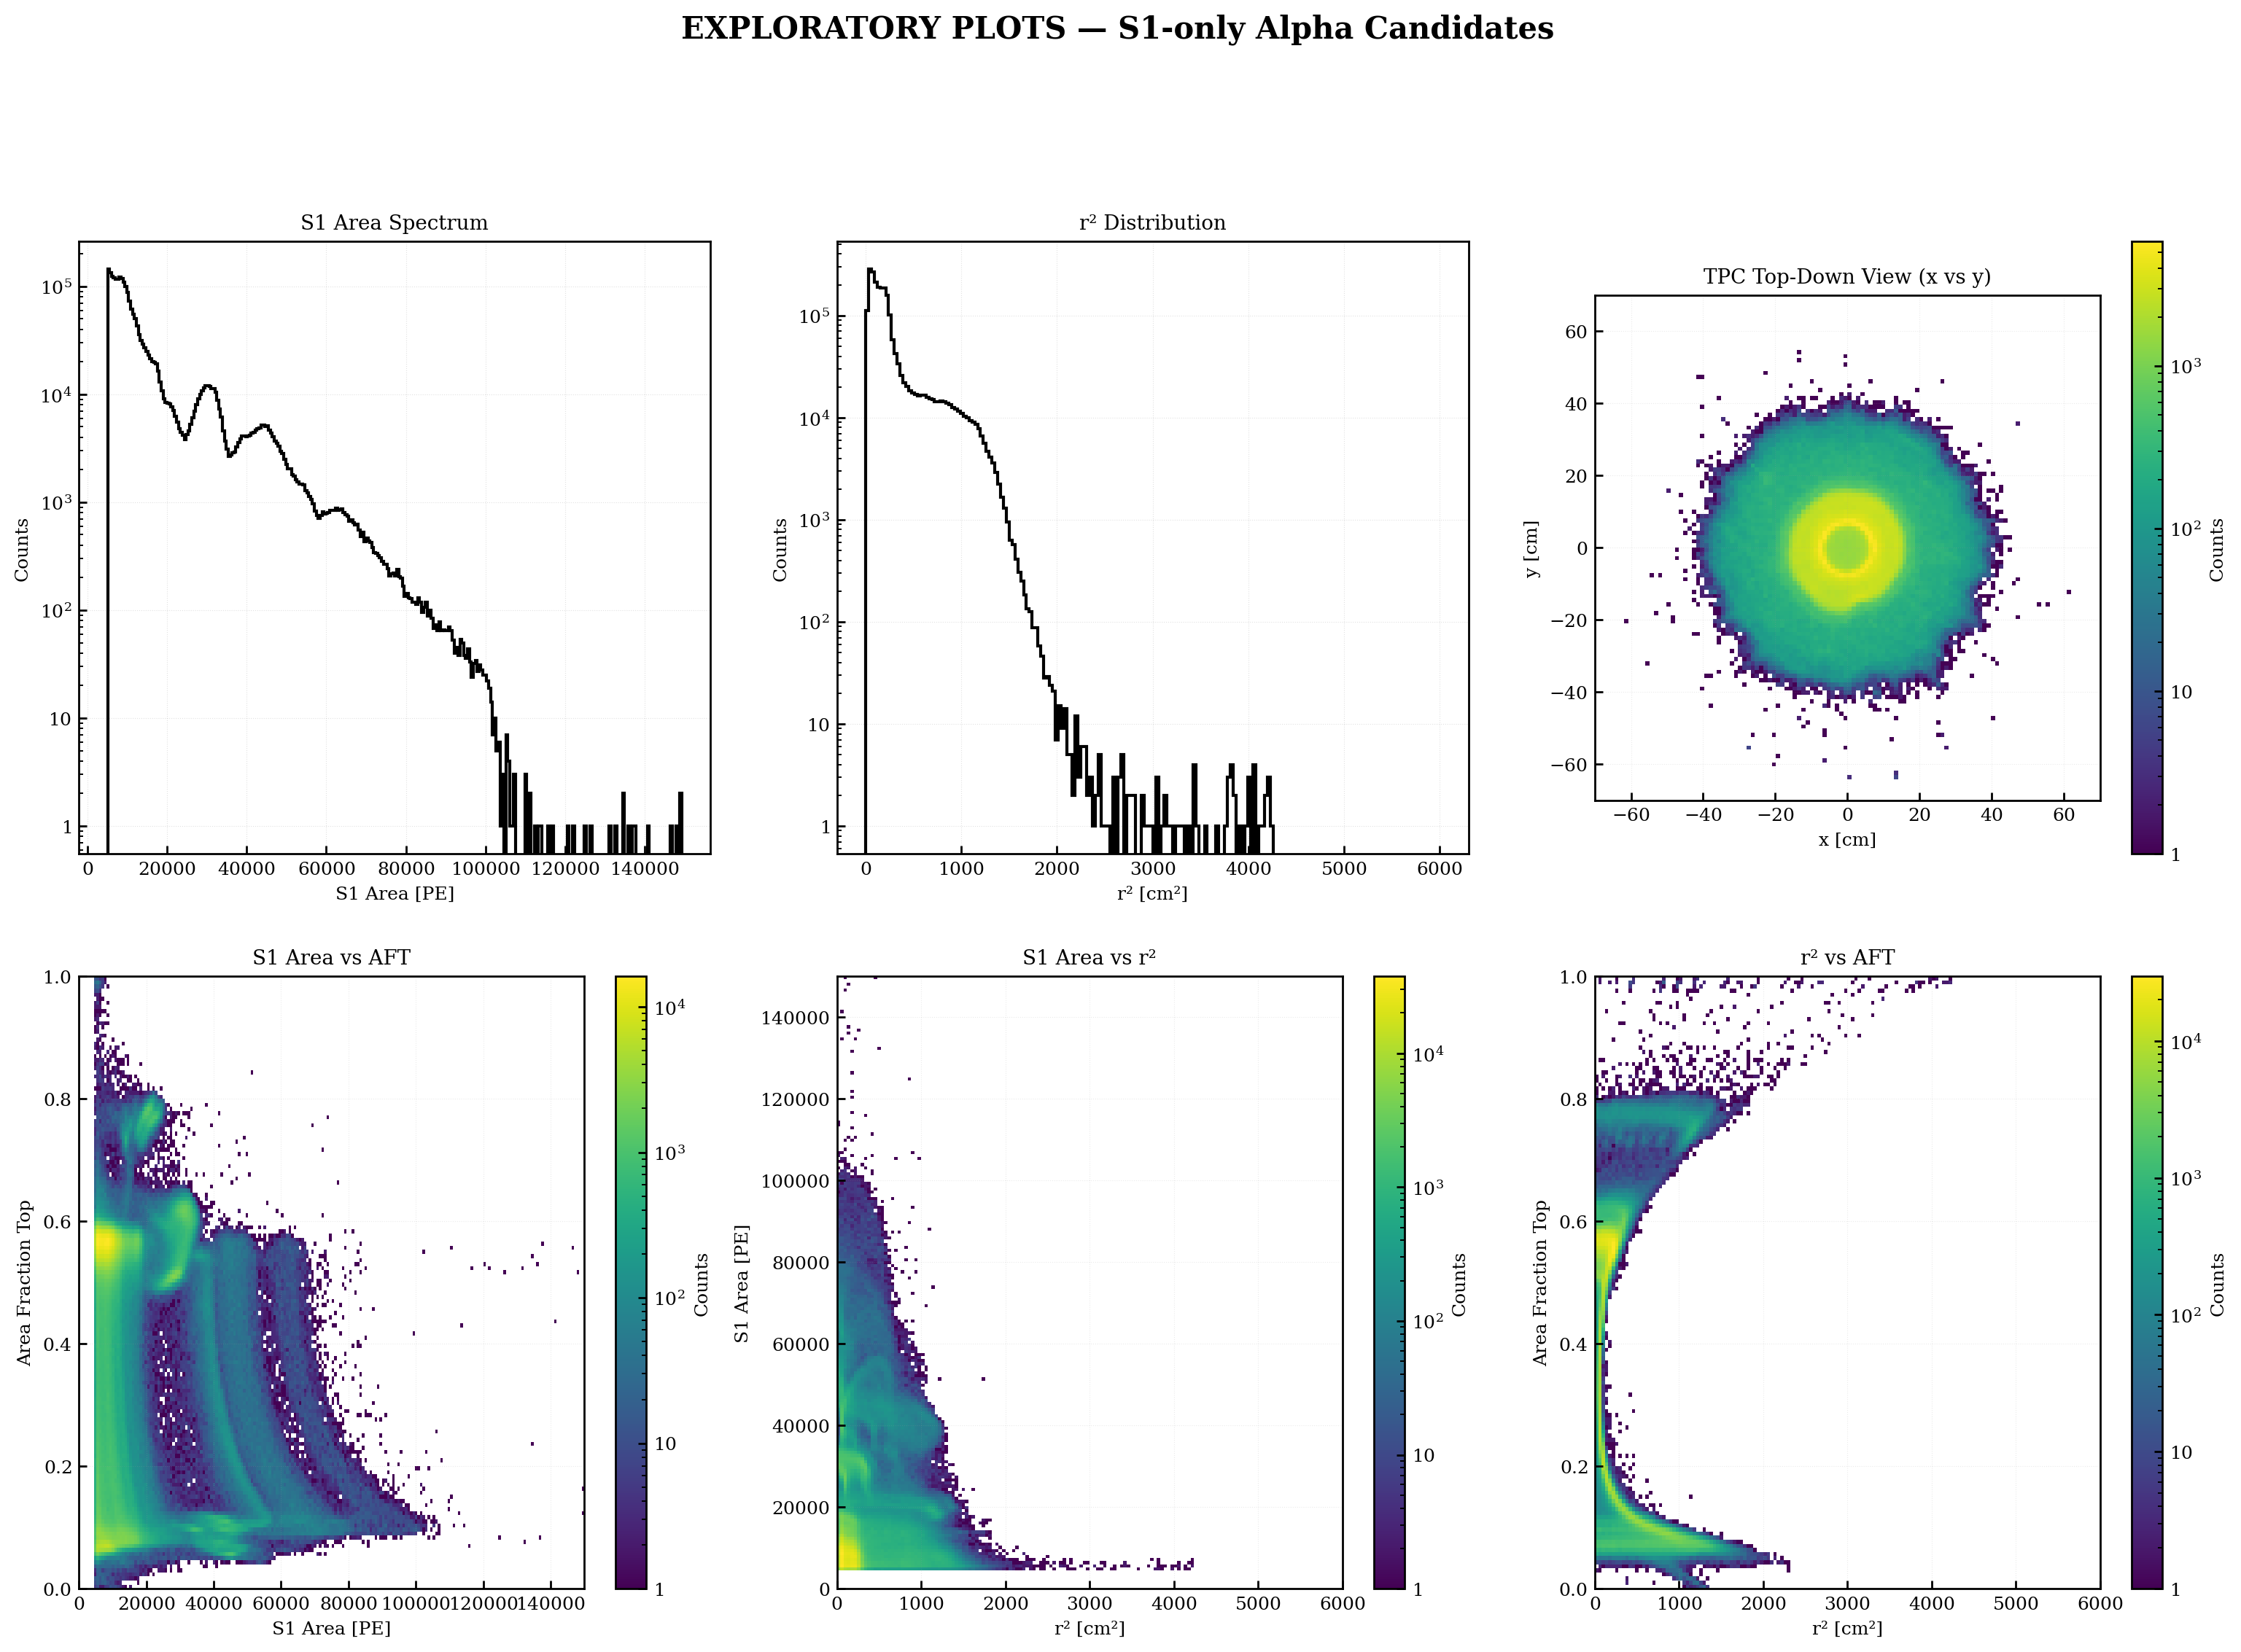

In [33]:
# ╔══════════════════════════════════════════════════════════════════════╗
# ║  EXPLORATORY PLOTS — see the data before defining cuts            ║
# ╚══════════════════════════════════════════════════════════════════════╝

d = df_peaks  # shorthand

# ── Statistics ──────────────────────────────────────────────────
print(f"Total S1 alpha candidates: {len(d):,}")
print(f"Columns: {list(d.columns)}")
print(f"  area:            [{d['area'].min():.0f}, {d['area'].max():.0f}] PE")
print(f"  area_fraction_top: [{d['area_fraction_top'].min():.3f}, {d['area_fraction_top'].max():.3f}]")
print(f"  range_50p_area:  [{d['range_50p_area'].min():.0f}, {d['range_50p_area'].max():.0f}] ns")
print(f"  r:               [{d['r'].min():.1f}, {d['r'].max():.1f}] cm")
print(f"  r2:              [{d['r2'].min():.1f}, {d['r2'].max():.1f}] cm²")

# ═══════════════════════════════════════════════════════════════════
# 6-PANEL EXPLORATORY PLOTS
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

# ── [0,0] S1 area 1D histogram ──────────────────────────────────
ax = axes[0, 0]
ax.hist(d['area'], bins=300, range=[d['area'].min(), d['area'].max()],
        histtype='step', color='black', lw=1.5)
ax.set_xlabel('S1 Area [PE]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('S1 Area Spectrum')
ax.grid(True, alpha=0.3)

# ── [0,1] r² 1D histogram ───────────────────────────────────────
ax = axes[0, 1]
ax.hist(d['r2'], bins=200, range=[0, 6e3],
        histtype='step', color='black', lw=1.5)
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('r² Distribution')
ax.grid(True, alpha=0.3)

# ── [0,2] x vs y (top-down view) ────────────────────────────────
ax = axes[0, 2]
h = ax.hist2d(d['x'], d['y'], bins=[120, 120],
              range=[[-70, 70], [-70, 70]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('x [cm]')
ax.set_ylabel('y [cm]')
ax.set_title('TPC Top-Down View (x vs y)')
ax.set_aspect('equal')
ax.grid(True, alpha=0.2)

# ── [1,0] S1 Area vs AFT ────────────────────────────────────────
ax = axes[1, 0]
h = ax.hist2d(d['area'], d['area_fraction_top'], bins=[200, 150],
              range=[[0, 150e3], [0, 1.0]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('S1 Area [PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('S1 Area vs AFT')
ax.grid(True, alpha=0.2)

# ── [1,1] S1 Area vs r² ─────────────────────────────────────────
ax = axes[1, 1]
h = ax.hist2d(d['r2'], d['area'], bins=[150, 200],
              range=[[0, 6e3], [0, 150e3]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('S1 Area [PE]')
ax.set_title('S1 Area vs r²')
ax.grid(True, alpha=0.2)

# ── [1,2] r² vs AFT ─────────────────────────────────────────────
ax = axes[1, 2]
h = ax.hist2d(d['r2'], d['area_fraction_top'], bins=[150, 150],
              range=[[0, 6e3], [0, 1.0]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('r² vs AFT')
ax.grid(True, alpha=0.2)

plt.suptitle('EXPLORATORY PLOTS — S1-only Alpha Candidates',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

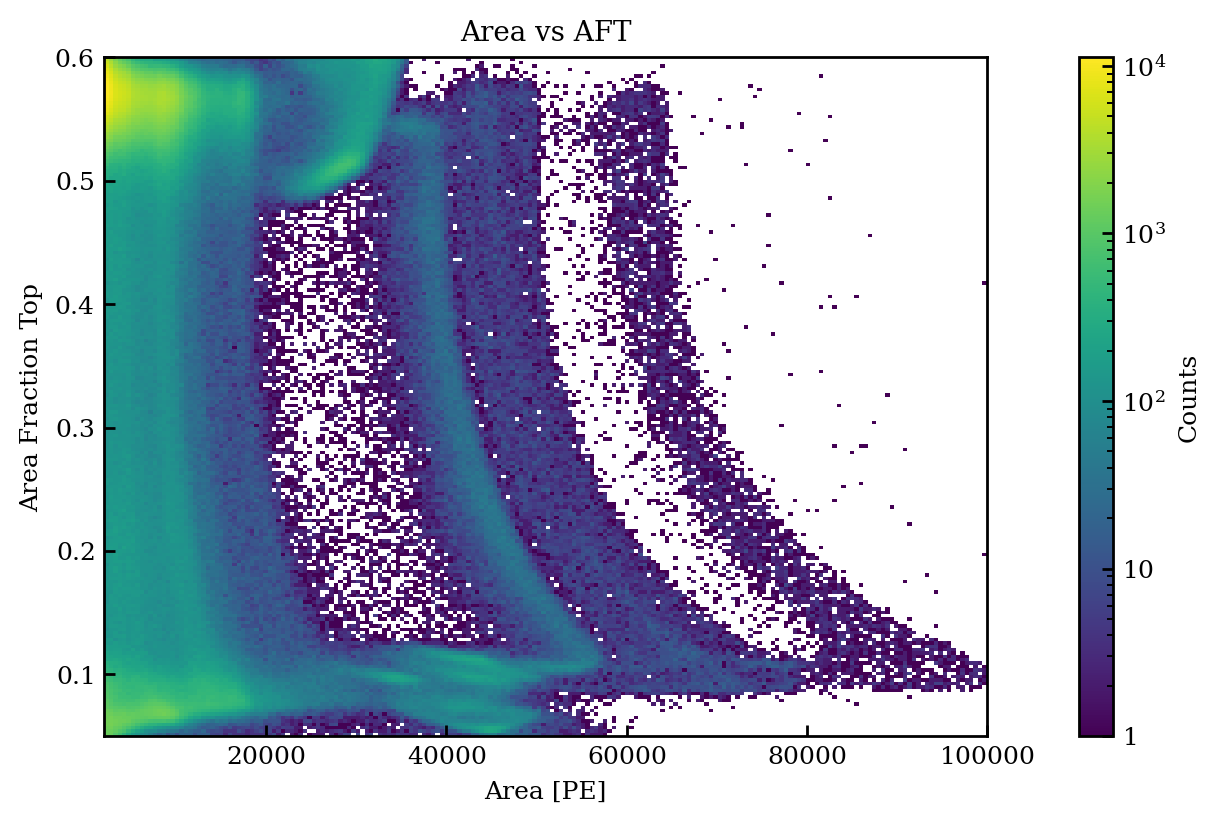

In [45]:
fig, ax = plt.subplots(figsize=(6,4))
h = ax.hist2d(
    df['area'], 
    df['area_fraction_top'],
    bins=[200, 200],
    range=[[2e3, 100e3], [0.05, 0.6]],
    cmin=1,
    norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('Area [PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('Area vs AFT')
plt.show()

Events in FV AFT range: 5325515
Events in Po-214 band: 44696


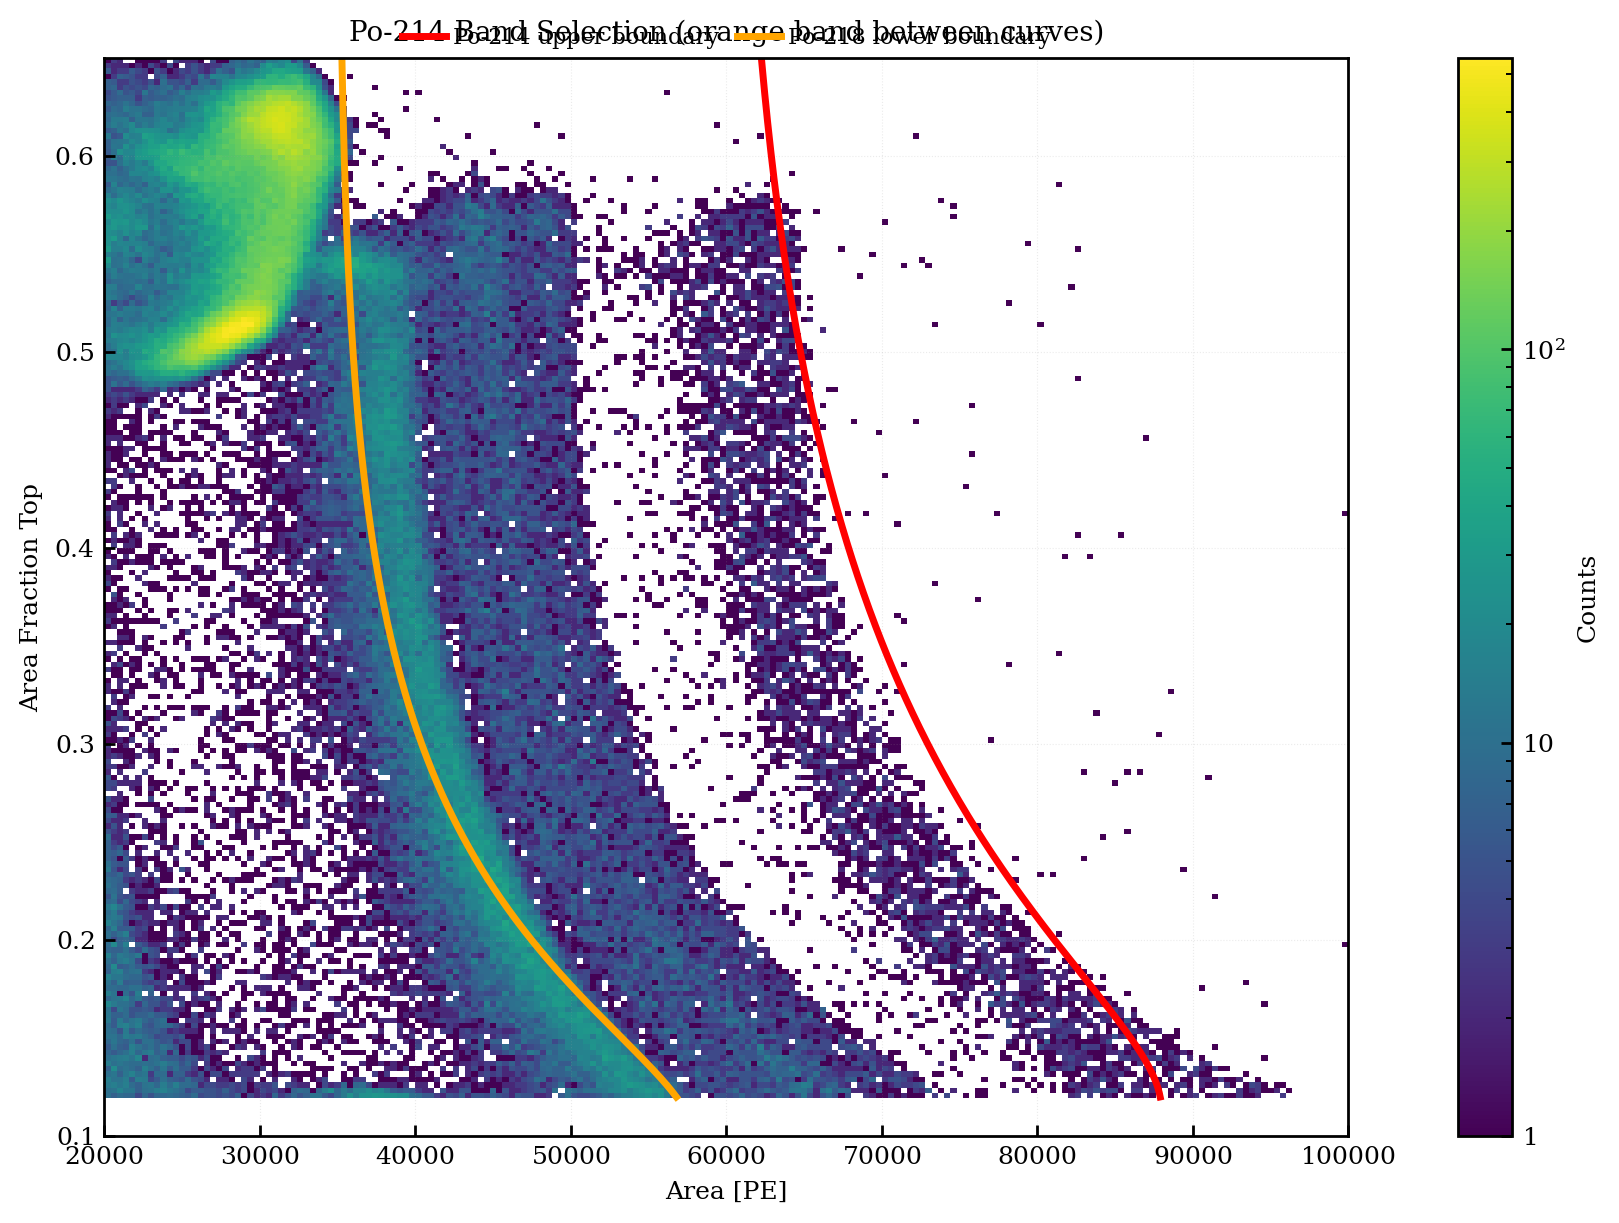

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ============================================================
# STEP 1: Define the bump model (the function you fit against)
# ============================================================

def exp_bump_model(x, a, b, c, d, e):
    """
    Florian's empirical model for area vs. AFT dependence.
    
    x = AFT (area_fraction_top)
    a = amplitude
    b = shift
    c, d = exponential scales
    e = offset
    
    Returns the expected area for a given AFT value.
    """
    return a * np.exp((x + b) / c) * (1 - np.exp((x + b) / d)) + e


# ============================================================
# STEP 2: Prepare data — keep only "good" AFT region
# ============================================================

# Remove gas band (high AFT ~0.8) and extreme bottoms
df_fv = df_peaks[
    (df_peaks['area_fraction_top'] > 0.12) & 
    (df_peaks['area_fraction_top'] < 0.65)
].copy()

print(f"Events in FV AFT range: {len(df_fv)}")


# ============================================================
# STEP 3: Manually define Po-214 band (brightest band)
# ============================================================
# Look at your area vs AFT 2D plot. Find the brightest (highest area) curved band.
# Define upper and lower boundaries that bracket ONLY this band.
# These parameters are for exp_bump_model(), not the fit result.

# Guesses for Po-214 band (adjust by eye after seeing the plot)
po214_upper_pars = [4.55e4, -4.88e-2, -0.2, -3.42e-2, 60e3]
po218_lower_pars = [4.55e4, -4.88e-2, -1.18e-1, -3.42e-2, 35e3]

# Tag events inside the Po-214 band
df_fv['in_po214'] = (
    (df_fv['area'] < exp_bump_model(df_fv['area_fraction_top'], *po214_upper_pars)) &
    (df_fv['area'] > exp_bump_model(df_fv['area_fraction_top'], *po218_lower_pars))
)

print(f"Events in Po-214 band: {df_fv['in_po214'].sum()}")


# ============================================================
# STEP 4: Plot to verify the band selection looks right
# ============================================================

fig, ax = plt.subplots(figsize=(8,6))

# Full 2D histogram
h = ax.hist2d(
    df_fv['area'], df_fv['area_fraction_top'],
    bins=[200, 200], 
    range=[[20e3, 100e3], [0.1, 0.65]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')

# Draw the two boundary curves
aft_fine = np.linspace(0.12, 0.65, 500)
ax.plot(exp_bump_model(aft_fine, *po214_upper_pars), aft_fine, 
        'r-', lw=2.5, label='Po-214 upper boundary')
ax.plot(exp_bump_model(aft_fine, *po218_lower_pars), aft_fine, 
        'orange', lw=2.5, label='Po-218 lower boundary')

ax.set_xlabel('Area [PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('Po-214 Band Selection (orange band between curves)')
ax.legend()
ax.grid(True, alpha=0.2)
plt.show()

# If the orange band doesn't look right, adjust the parameter lists above

Events in FV AFT range [0.12, 0.55]: 2917851
Events bracketed by Rn boundaries: 36530
AFT bins with Rn data: 50
Median area range: 36370 - 53940 PE

=== Rn-222/220 FIT RESULTS ===
a (amplitude) = 1.82e+04 ± 6.18e+05
b (shift)     = -0.119559 ± 4.461777
c (scale1)    = -0.131566 ± 0.002608
d (scale2)    = -0.001015 ± 0.916796
e (offset)    = 3.65e+04 ± 9.39e+01


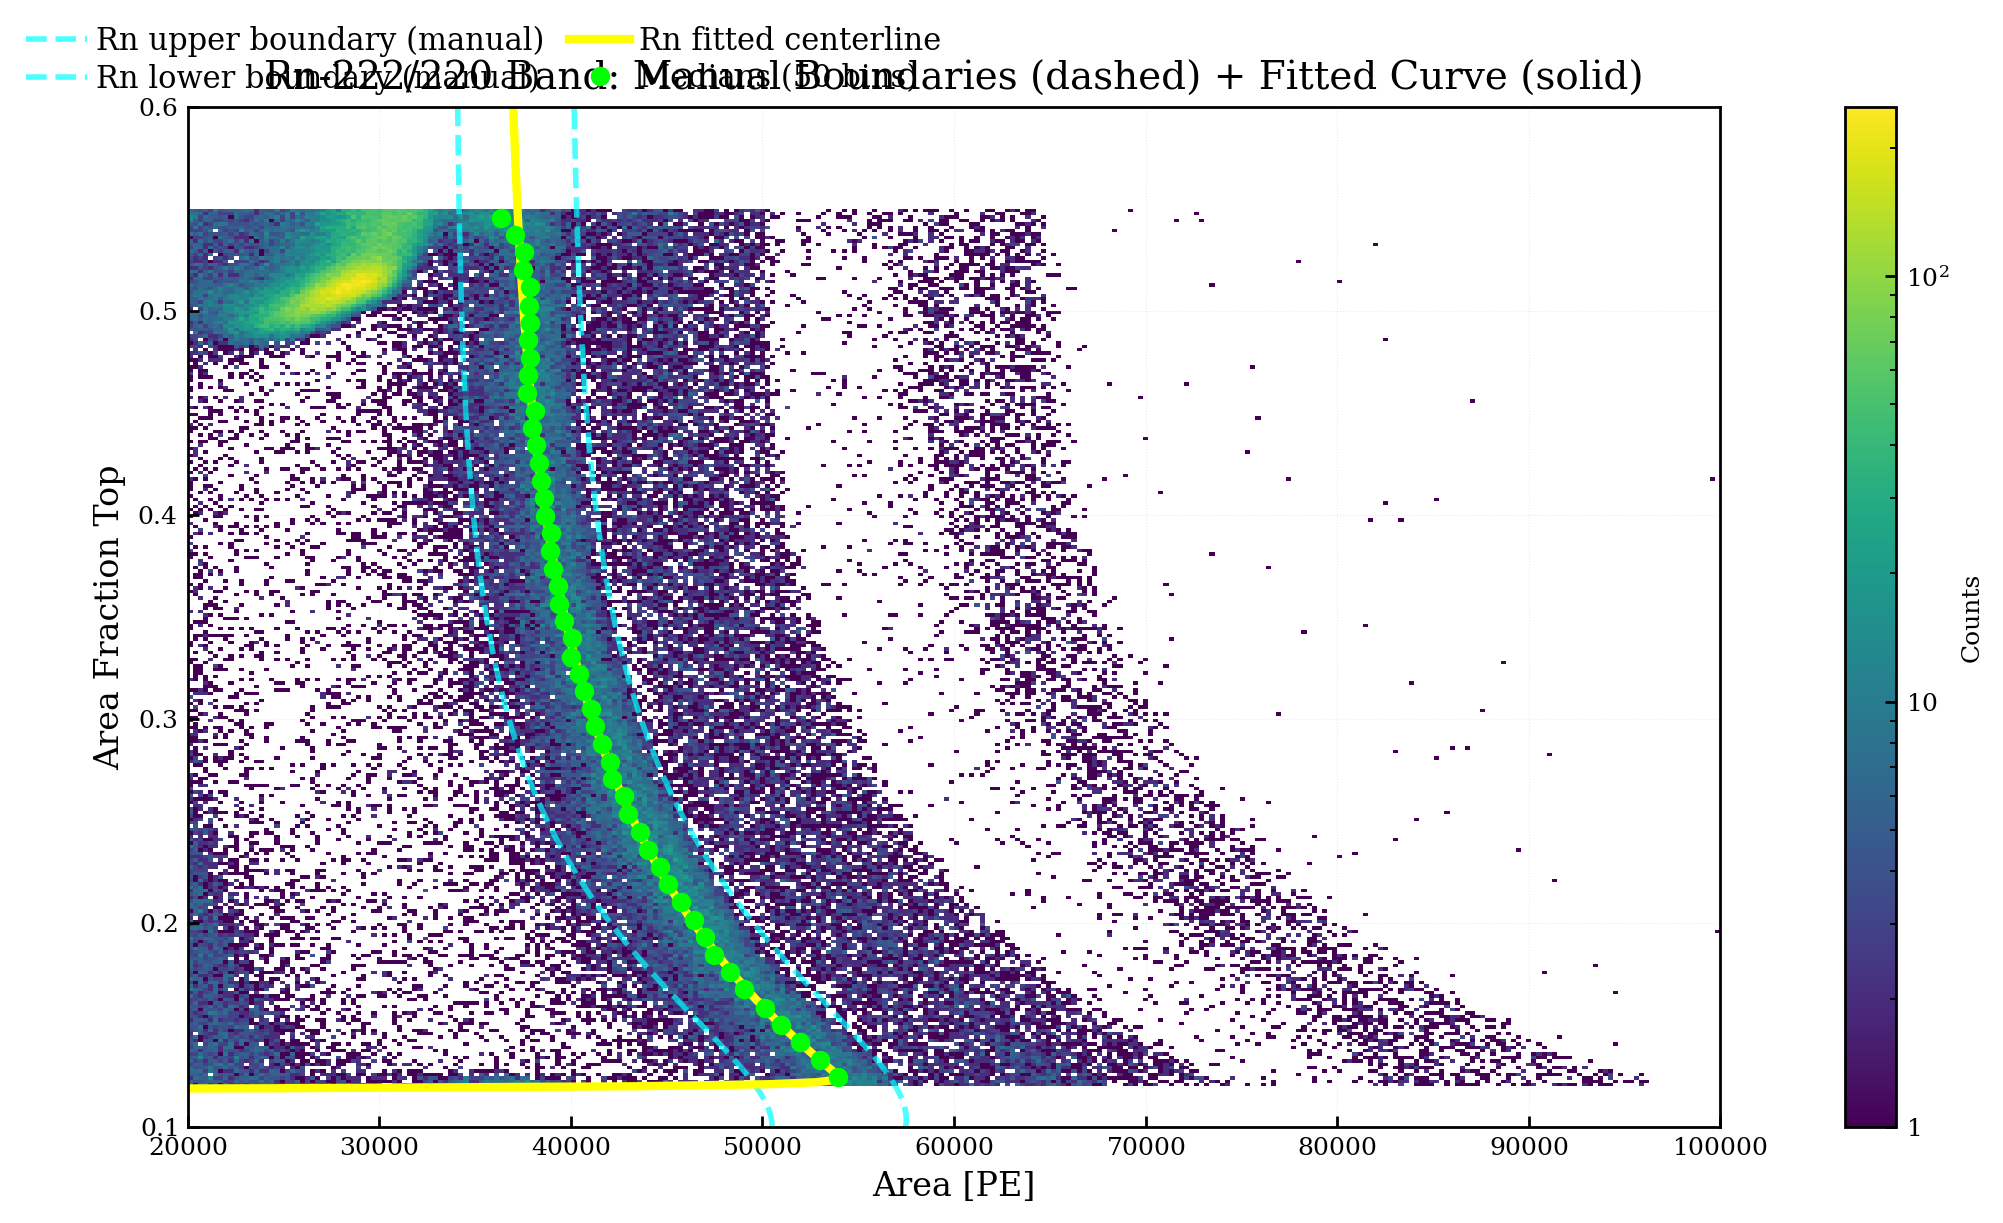

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import matplotlib

def exp_bump_model(x, a, b, c, d, e):
    """Florian's empirical model for area vs. AFT dependence."""
    return a * np.exp((x + b) / c) * (1 - np.exp((x + b) / d)) + e


# ============================================================
# STEP 1: Data prep — FV range only
# ============================================================

df_fv = df_peaks[
    (df_peaks['area_fraction_top'] >= 0.12) & 
    (df_peaks['area_fraction_top'] <= 0.55)
].copy()

print(f"Events in FV AFT range [0.12, 0.55]: {len(df_fv)}")


# ============================================================
# STEP 2: Define manual boundaries for Rn-222/220 band
# ============================================================
# These are TEMPORARY guesses to select which events to fit.
# Adjust these parameters by eye after seeing the plot.

rn_upper_pars = [4.55e4, -4.88e-2, -0.1, -0.05, 40e3]
rn_lower_pars = [4.55e4, -4.88e-2, -0.09, -0.05, 34e3]

df_fv['in_rn_band'] = (
    (df_fv['area'] < exp_bump_model(df_fv['area_fraction_top'], *rn_upper_pars)) &
    (df_fv['area'] > exp_bump_model(df_fv['area_fraction_top'], *rn_lower_pars))
)

print(f"Events bracketed by Rn boundaries: {df_fv['in_rn_band'].sum()}")


# ============================================================
# STEP 3: Bin Rn events in AFT slices and get medians
# ============================================================

n_aft_bins = 50
aft_edges = np.linspace(0.12, 0.55, n_aft_bins + 1)
df_fv['aft_bin'] = pd.cut(df_fv['area_fraction_top'], bins=aft_edges)

medians_rn = (
    df_fv[df_fv['in_rn_band']]
    .groupby('aft_bin', observed=True)['area']
    .median()
)

aft_centers = medians_rn.index.map(lambda iv: iv.mid).astype(float).values
median_values = medians_rn.values

print(f"AFT bins with Rn data: {len(aft_centers)}")
print(f"Median area range: {median_values.min():.0f} - {median_values.max():.0f} PE")


# ============================================================
# STEP 4: Fit the bump model to Rn medians
# ============================================================

p0_rn = [4.55e4, -0.05, -0.1, -0.05, 35e3]
p_opt_rn, p_cov_rn = curve_fit(
    exp_bump_model,
    aft_centers,
    median_values,
    p0=p0_rn,
    bounds=([0, -np.inf, -np.inf, -np.inf, 0],
            [np.inf, 0, 0, 0, np.inf]),
    maxfev=10000
)

p_err_rn = np.sqrt(np.diag(p_cov_rn))

print("\n=== Rn-222/220 FIT RESULTS ===")
print(f"a (amplitude) = {p_opt_rn[0]:.2e} ± {p_err_rn[0]:.2e}")
print(f"b (shift)     = {p_opt_rn[1]:.6f} ± {p_err_rn[1]:.6f}")
print(f"c (scale1)    = {p_opt_rn[2]:.6f} ± {p_err_rn[2]:.6f}")
print(f"d (scale2)    = {p_opt_rn[3]:.6f} ± {p_err_rn[3]:.6f}")
print(f"e (offset)    = {p_opt_rn[4]:.2e} ± {p_err_rn[4]:.2e}")


# ============================================================
# STEP 5: Plot everything
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

# Full 2D histogram (all data in FV range)
h = ax.hist2d(
    df_fv['area'], df_fv['area_fraction_top'],
    bins=[300, 300],
    range=[[20e3, 100e3], [0.1, 0.6]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
cbar = plt.colorbar(h[3], ax=ax, label='Counts')

# Fine grid for plotting curves
aft_fine = np.linspace(0.10, 0.60, 500)

# DASHED lines: manual boundaries (temporary)
ax.plot(exp_bump_model(aft_fine, *rn_upper_pars), aft_fine,
        '--', color='cyan', lw=2, alpha=0.7, label='Rn upper boundary (manual)')
ax.plot(exp_bump_model(aft_fine, *rn_lower_pars), aft_fine,
        '--', color='cyan', lw=2, alpha=0.7, label='Rn lower boundary (manual)')

# SOLID line: fitted centerline
ax.plot(exp_bump_model(aft_fine, *p_opt_rn), aft_fine,
        '-', color='yellow', lw=3, label='Rn fitted centerline')

# Cyan dots: median points used in fit
ax.plot(median_values, aft_centers, 'o', color='lime', markersize=6,
        label=f'Medians ({len(aft_centers)} bins)', zorder=5)

# Annotations
ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('Rn-222/220 Band: Manual Boundaries (dashed) + Fitted Curve (solid)', fontsize=14)
ax.legend(fontsize=11, loc='lower right')
ax.grid(True, alpha=0.2)

plt.show()


Reference AFT: 0.3
Reference area (Rn centerline at AFT=0.3): 41151 PE
Correction applied to 2917851 events


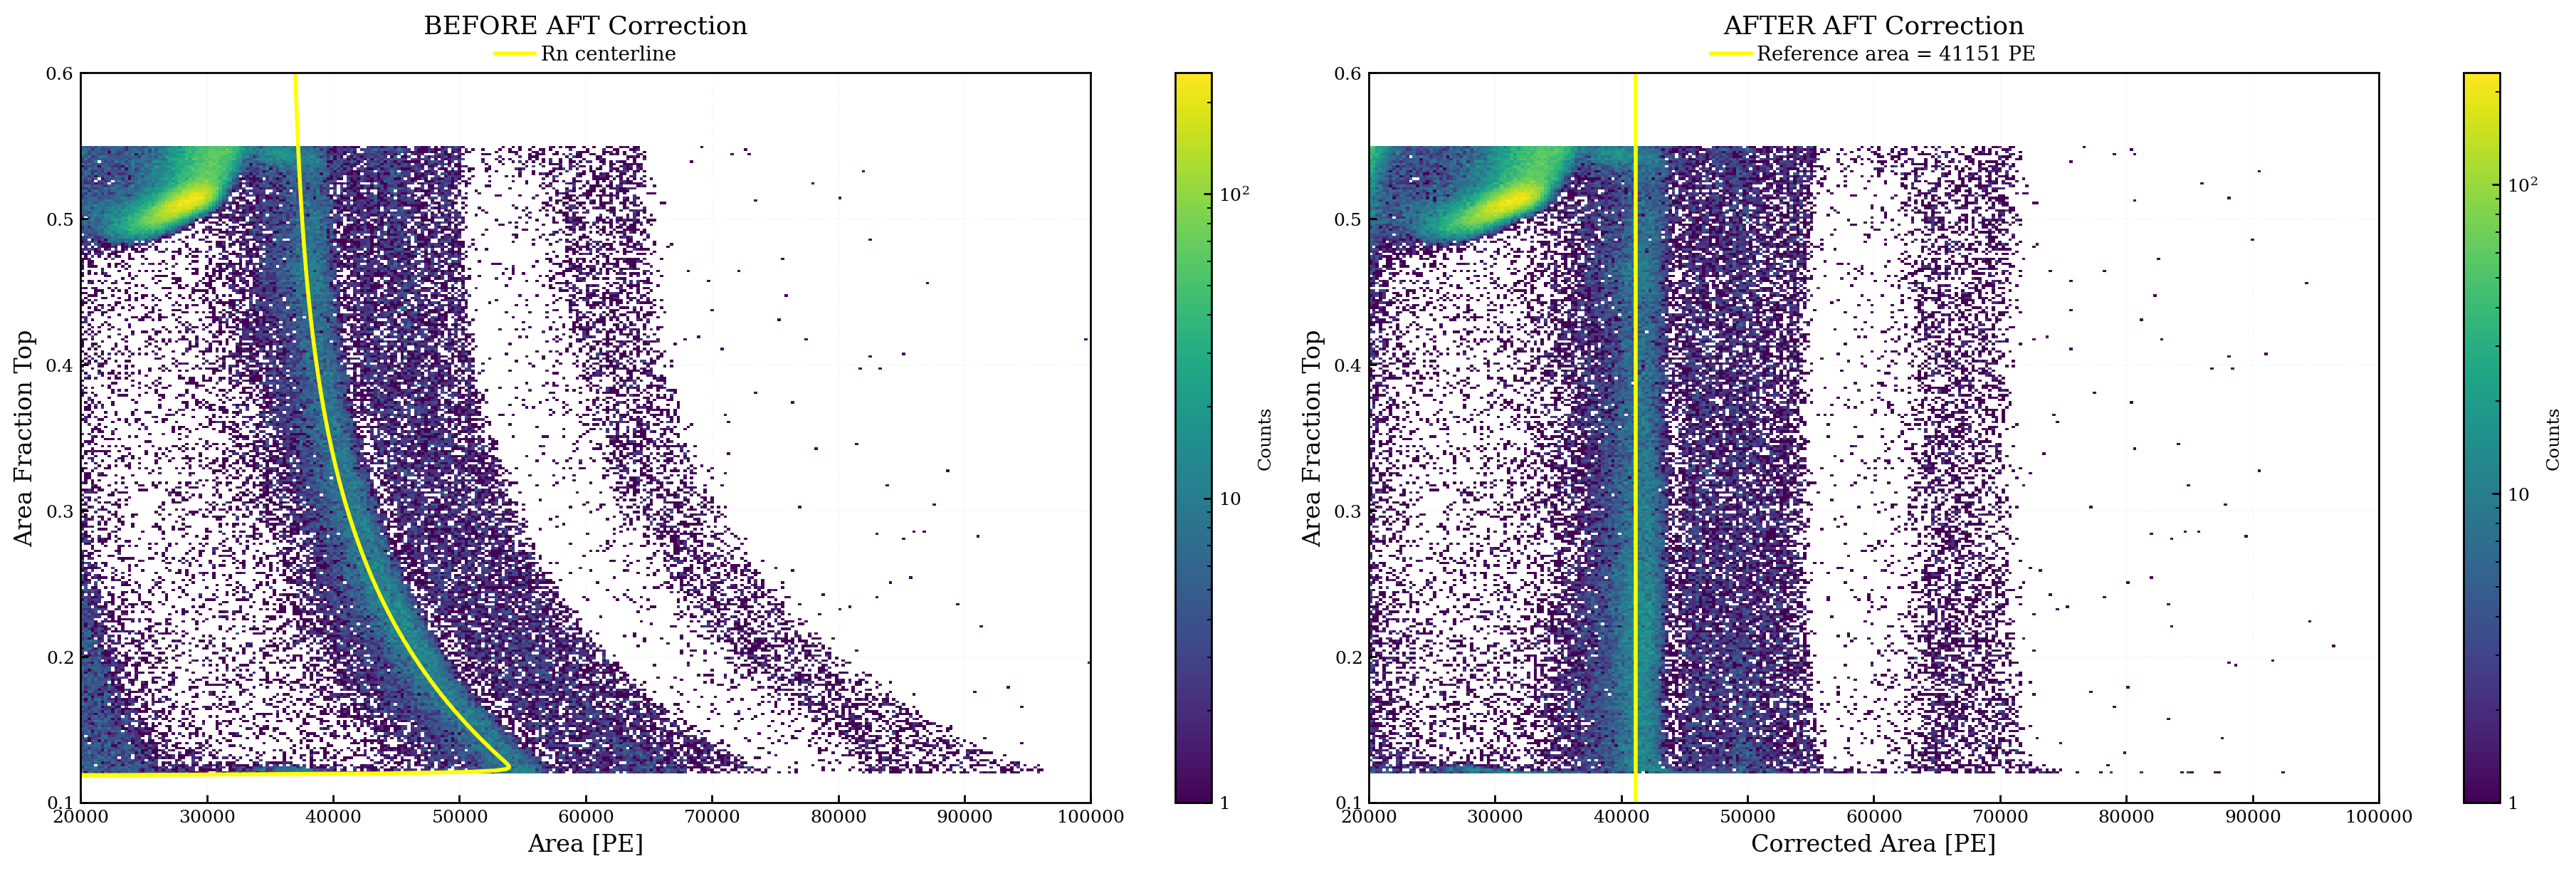

<Figure size 675x544 with 0 Axes>

In [84]:
# ============================================================
# STEP 6: Apply AFT correction to all events
# ============================================================

# Choose a reference AFT value (somewhere in the middle of your range)
aft_ref = 0.30

# Calculate the reference area at this AFT
area_ref_rn = exp_bump_model(aft_ref, *p_opt_rn)

print(f"\nReference AFT: {aft_ref}")
print(f"Reference area (Rn centerline at AFT={aft_ref}): {area_ref_rn:.0f} PE")

# Apply correction: normalize all areas to the reference AFT
# corrected_area = raw_area * (area_at_ref_AFT / area_at_observed_AFT)
df_fv['area_corrected_rn'] = (
    df_fv['area'] 
    * area_ref_rn 
    / exp_bump_model(df_fv['area_fraction_top'], *p_opt_rn)
)

print(f"Correction applied to {len(df_fv)} events")


# ============================================================
# STEP 7: Plot before/after correction
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# BEFORE correction
ax = axes[0]
h = ax.hist2d(
    df_fv['area'], df_fv['area_fraction_top'],
    bins=[300, 300],
    range=[[20e3, 100e3], [0.1, 0.6]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.plot(exp_bump_model(aft_fine, *p_opt_rn), aft_fine,
        '-', color='yellow', lw=2, label='Rn centerline')
ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('BEFORE AFT Correction', fontsize=13, pad=20)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)

# AFTER correction
ax = axes[1]
h = ax.hist2d(
    df_fv['area_corrected_rn'], df_fv['area_fraction_top'],
    bins=[300, 300],
    range=[[20e3, 100e3], [0.1, 0.6]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axvline(x=area_ref_rn, color='yellow', lw=2, linestyle='-', label=f'Reference area = {area_ref_rn:.0f} PE')
ax.set_xlabel('Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('AFTER AFT Correction', fontsize=13, pad=20)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)

plt.show()
plt.savefig("rn_band_correction_before_after.png")

Rn-222/220 events for rate calculation: 36530


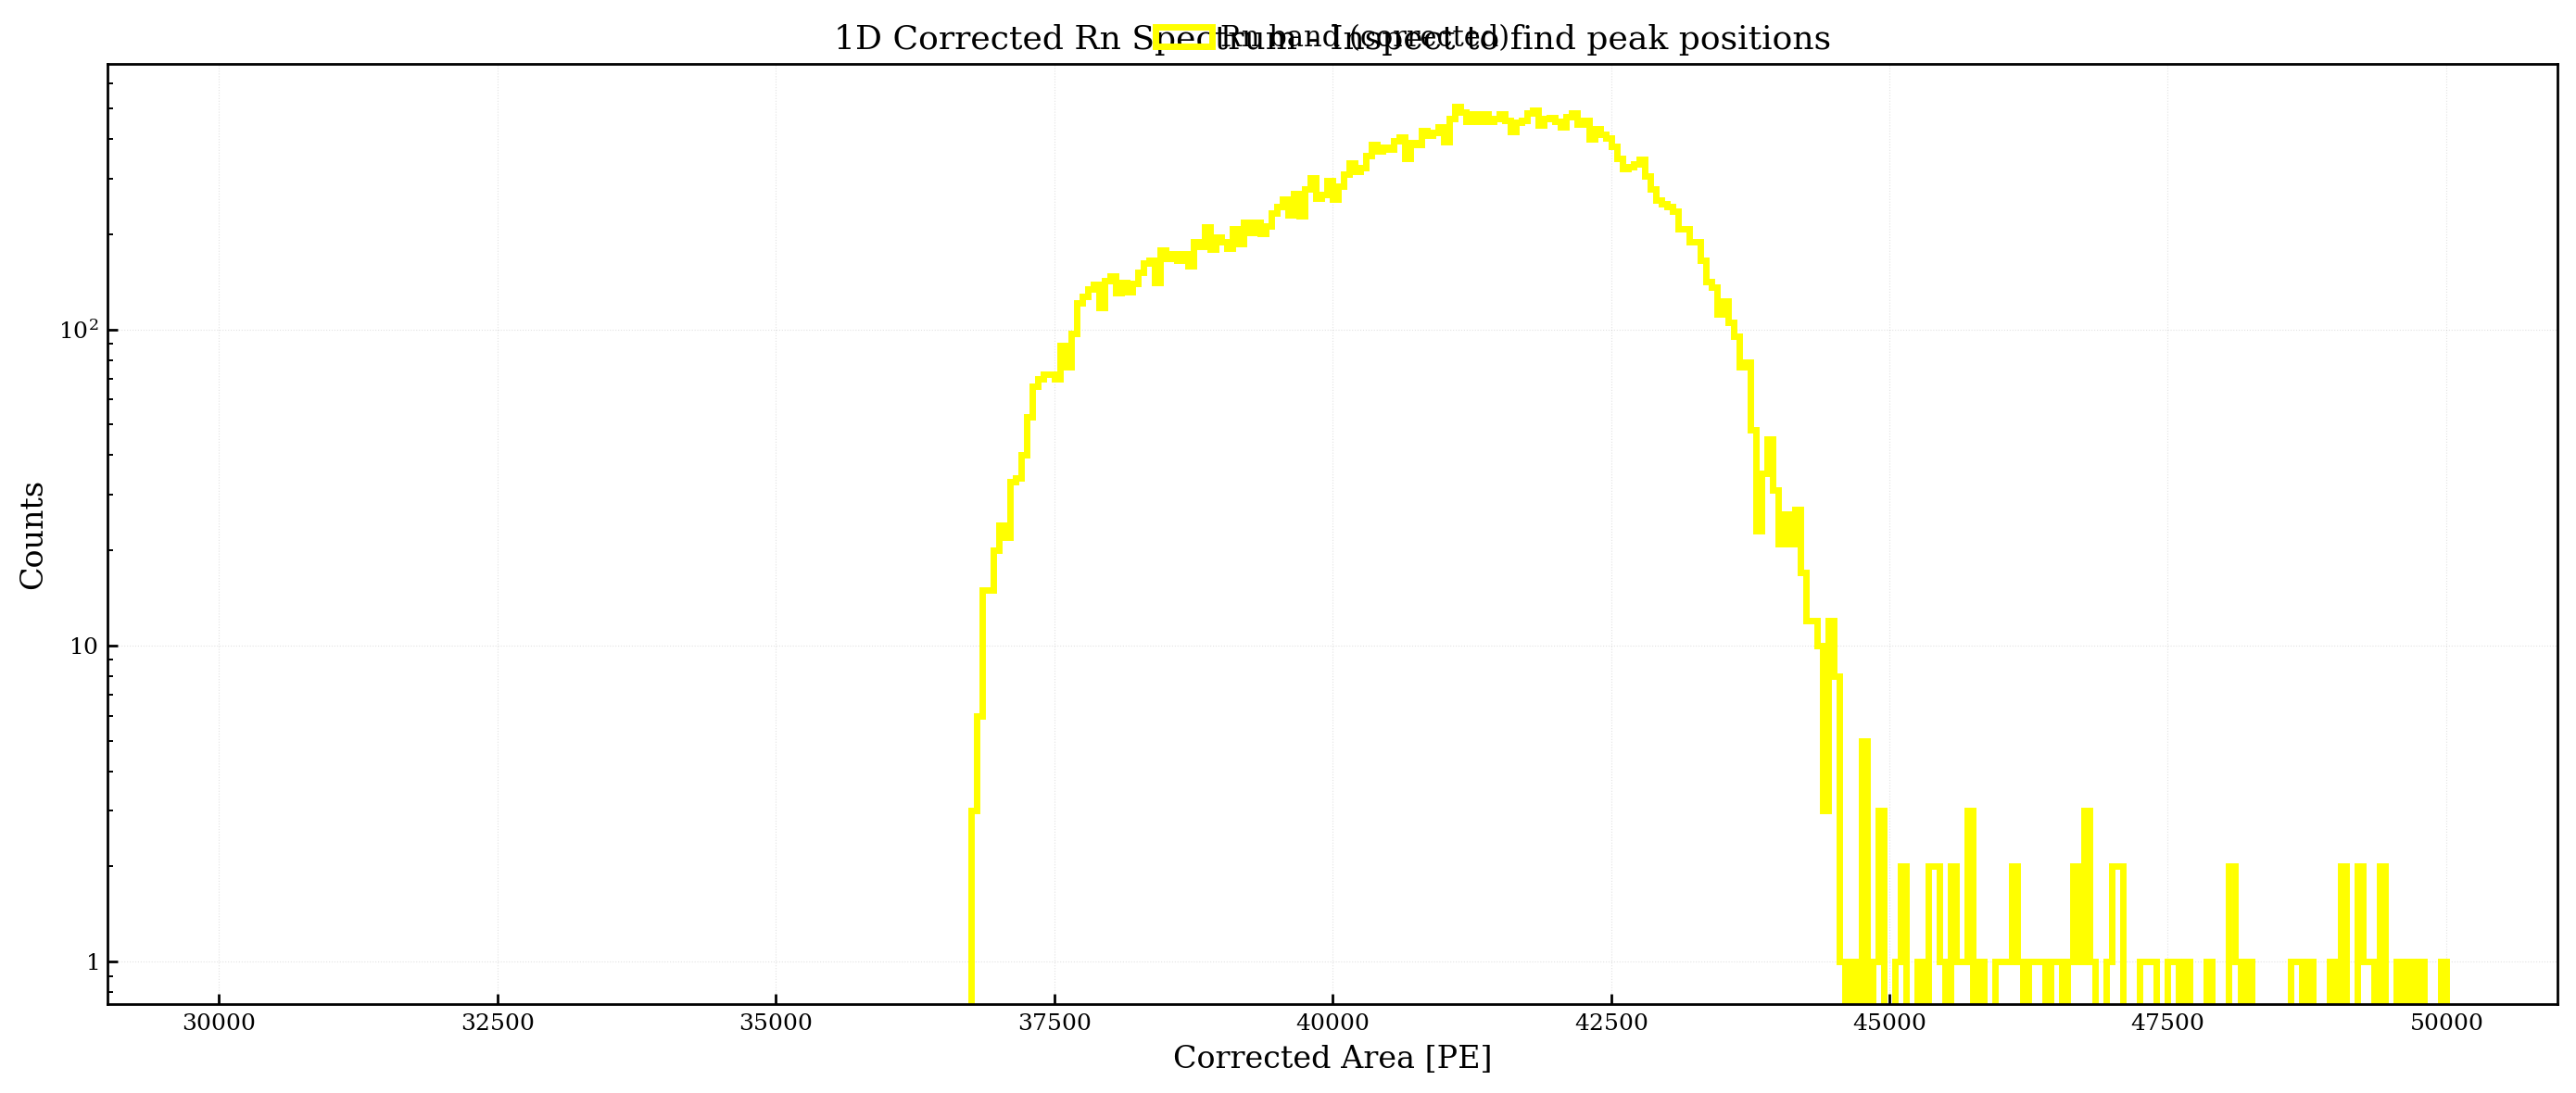


Spectrum range: 30000 - 50000 PE
Max bin count: 506.0
Total counts: 36511.0

Rough peak positions detected:
  37550 PE (height: 89)
  38750 PE (height: 190)
  39800 PE (height: 301)
  41100 PE (height: 506)
  42150 PE (height: 483)
  43500 PE (height: 123)


In [86]:
# ============================================================
# STEP 9: Plot 1D corrected Rn spectrum for inspection
# ============================================================

# Use only Rn-corrected events (from Rn band)
rn_events = df_fv[df_fv['in_rn_band']].copy()

print(f"Rn-222/220 events for rate calculation: {len(rn_events)}")

# Plot 1D corrected spectrum
fig, ax = plt.subplots(figsize=(14, 6))

counts_rn, edges_rn, _ = ax.hist(
    rn_events['area_corrected_rn'], 
    bins=400, 
    range=[30e3, 50e3],
    histtype='step', 
    color='yellow', 
    lw=2.5,
    label='Rn band (corrected)'
)

ax.set_xlabel('Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Counts', fontsize=12)
ax.set_yscale('log')
ax.set_title('1D Corrected Rn Spectrum - Inspect to find peak positions', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print some stats
print(f"\nSpectrum range: {edges_rn[0]:.0f} - {edges_rn[-1]:.0f} PE")
print(f"Max bin count: {counts_rn.max()}")
print(f"Total counts: {counts_rn.sum()}")

# Find rough peak positions (local maxima)
from scipy.signal import find_peaks
peaks_idx, peaks_props = find_peaks(counts_rn, height=counts_rn.max()*0.1, distance=20)
peak_positions = edges_rn[peaks_idx]
peak_heights = counts_rn[peaks_idx]

print(f"\nRough peak positions detected:")
for pos, height in zip(peak_positions, peak_heights):
    print(f"  {pos:.0f} PE (height: {height:.0f})")


=== SINGLE GAUSSIAN FIT ===
Amplitude: 462.2 ± 12.8
Mean (μ):  40943 ± 36 PE
Sigma (σ): 1434 ± 26 PE
Background: -0.4 ± 0.9


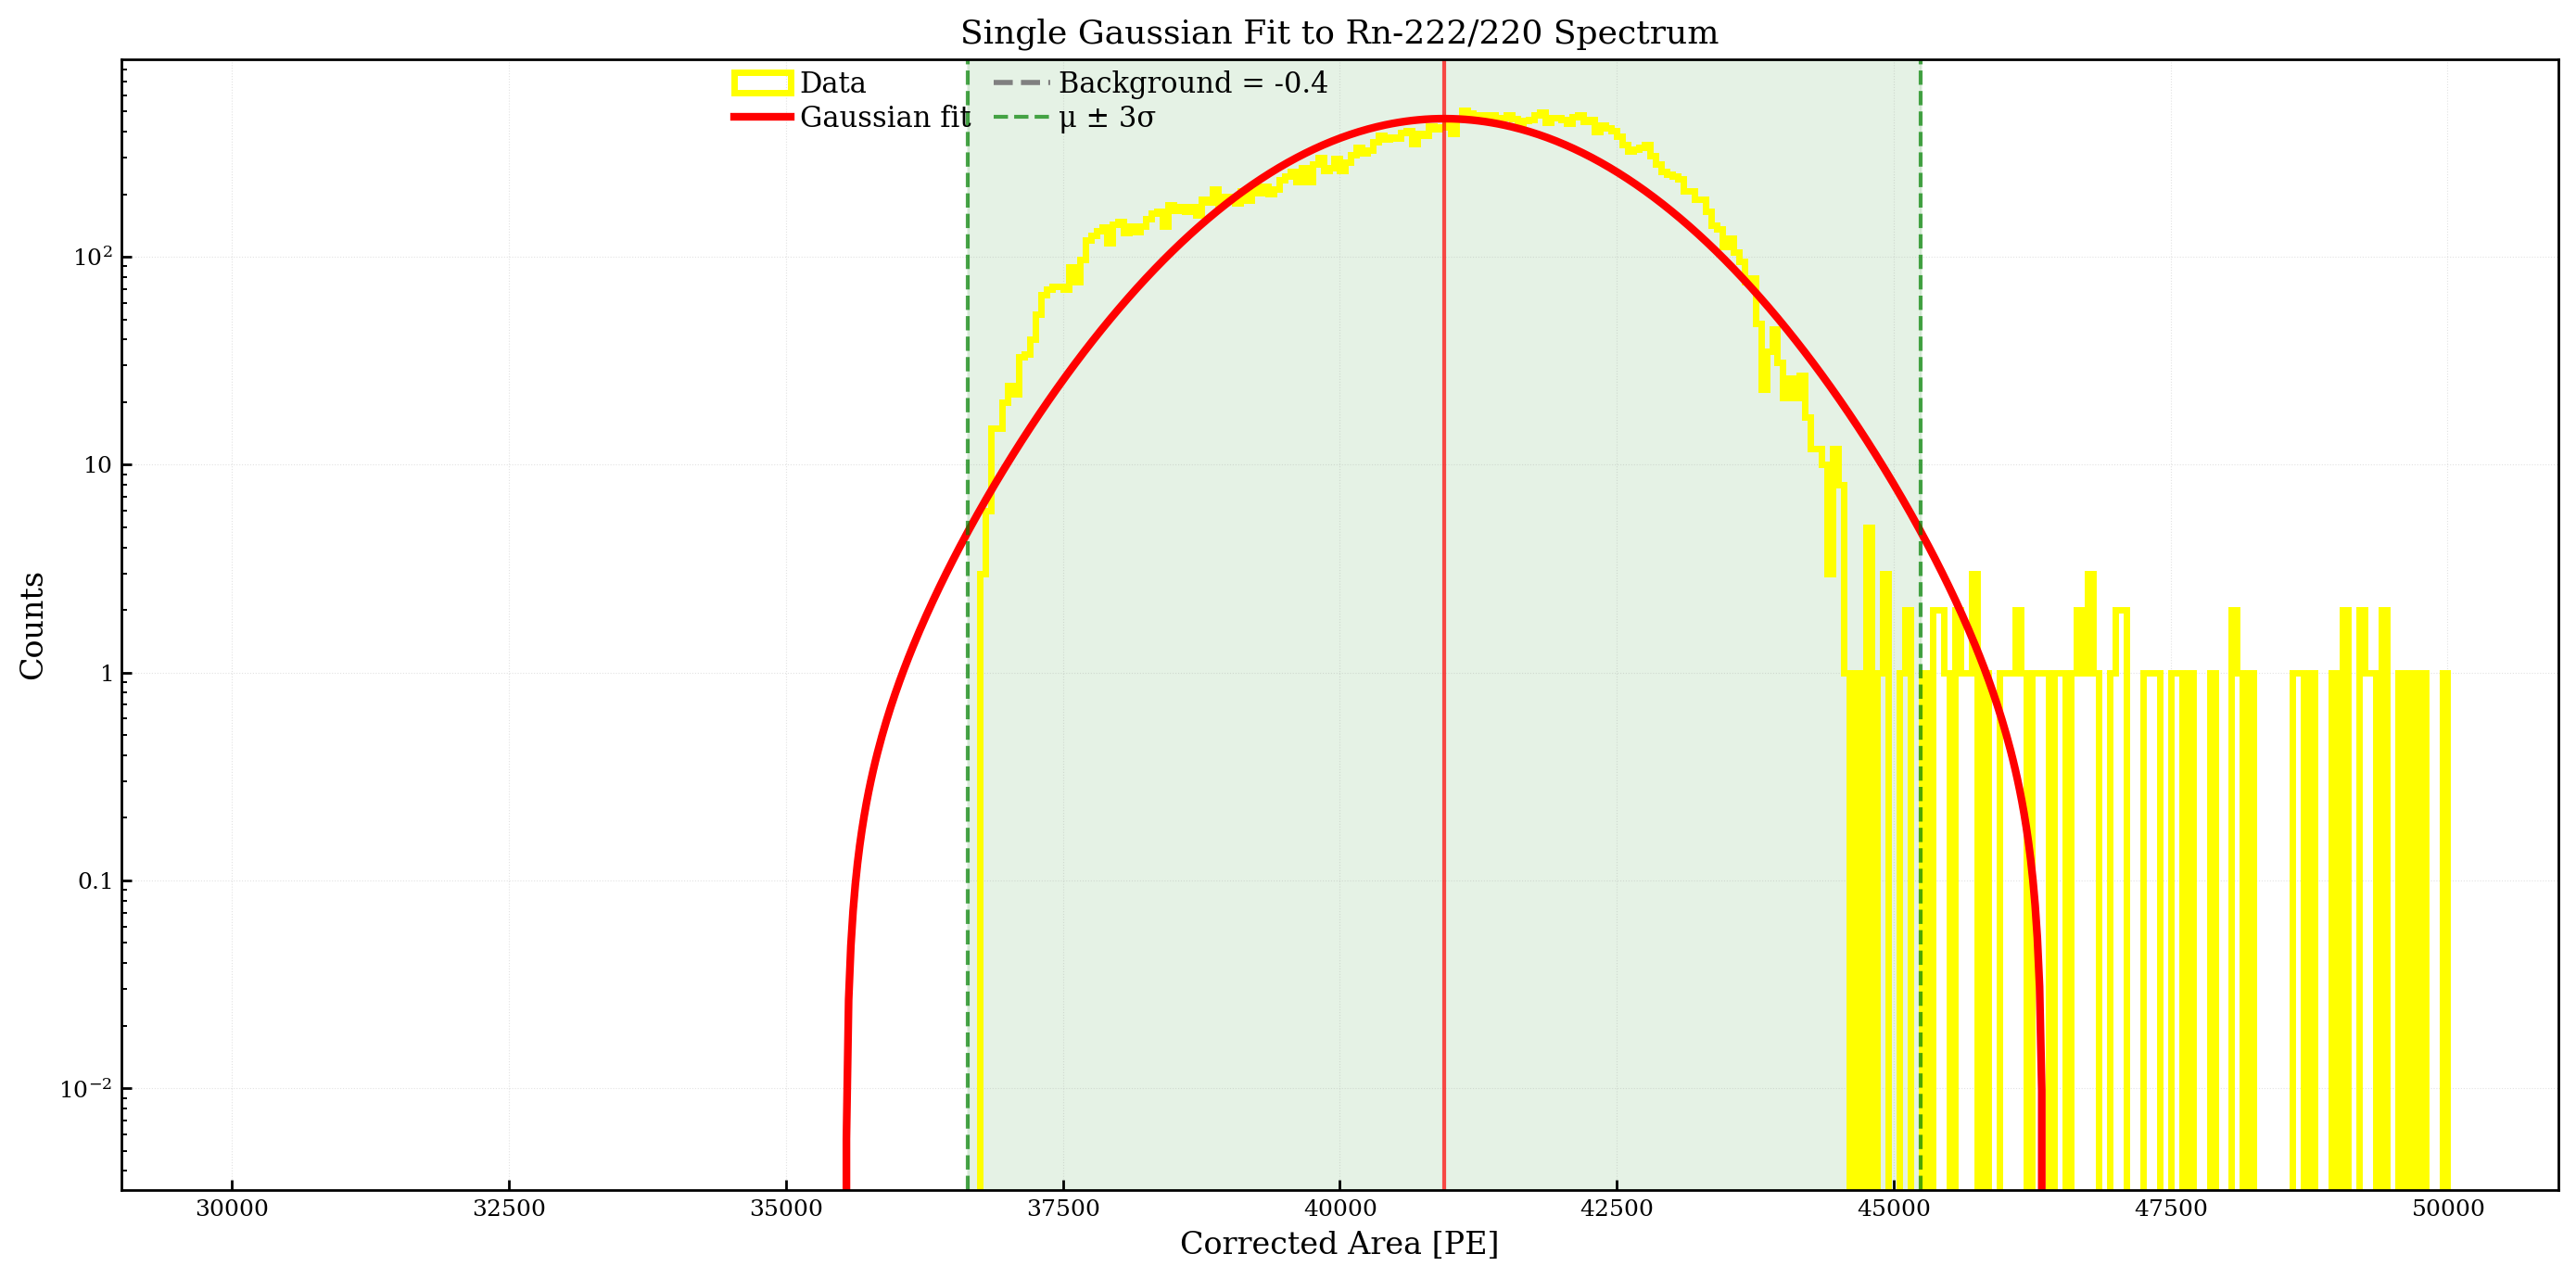


=== Rn RATE CALCULATION ===
Peak position: 40943 PE
Peak width (σ): 1434 PE
Counting window [μ-3σ, μ+3σ]: [36642, 45244] PE
Events in counting window: 36446

Livetime: 1033635.0 s (287.12 hours)
Rn rate: 0.0353 ± 0.0002 Hz
Rn rate: 35260.03 ± 184.70 μHz


In [87]:
# ============================================================
# STEP 10: Fit single Gaussian to Rn spectrum
# ============================================================

from scipy.optimize import curve_fit as scipy_curve_fit

def gaussian(x, a, mu, sig, bg):
    """Single Gaussian + constant background."""
    return a * np.exp(-0.5 * ((x - mu) / sig) ** 2) + bg

# Prepare data for fitting
bin_centers = 0.5 * (edges_rn[:-1] + edges_rn[1:])
mask_fit = counts_rn > 0

# Initial guesses from the plot you showed
p0_single = [
    500,      # amplitude
    41100,    # mean (from detected peak)
    2500,     # sigma (rough width)
    1.0       # background
]

try:
    p_fit, p_cov_fit = scipy_curve_fit(
        gaussian,
        bin_centers[mask_fit],
        counts_rn[mask_fit],
        p0=p0_single,
        maxfev=10000,
        sigma=np.sqrt(counts_rn[mask_fit] + 1)  # Poisson errors
    )
    p_err = np.sqrt(np.diag(p_cov_fit))
    
except Exception as e:
    print(f"Fit failed: {e}")
    p_fit = None

if p_fit is not None:
    a_fit, mu_fit, sig_fit, bg_fit = p_fit
    
    print("\n=== SINGLE GAUSSIAN FIT ===")
    print(f"Amplitude: {a_fit:.1f} ± {p_err[0]:.1f}")
    print(f"Mean (μ):  {mu_fit:.0f} ± {p_err[1]:.0f} PE")
    print(f"Sigma (σ): {sig_fit:.0f} ± {p_err[2]:.0f} PE")
    print(f"Background: {bg_fit:.1f} ± {p_err[3]:.1f}")
    
    # ============================================================
    # STEP 11: Plot fit result
    # ============================================================
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    # Data
    ax.hist(rn_events['area_corrected_rn'], bins=400, range=[30e3, 50e3],
            histtype='step', color='yellow', lw=2.5, label='Data')
    
    # Fitted curve
    x_fine = np.linspace(30e3, 50e3, 1000)
    ax.plot(x_fine, gaussian(x_fine, *p_fit), 'r-', lw=3, label='Gaussian fit')
    
    # Components
    ax.axhline(y=bg_fit, color='gray', ls='--', lw=2, label=f'Background = {bg_fit:.1f}')
    
    # ±3σ region
    sig_3 = 3 * sig_fit
    ax.axvline(mu_fit, color='red', ls='-', lw=1.5, alpha=0.7)
    ax.axvline(mu_fit - sig_3, color='green', ls='--', lw=1.5, alpha=0.7, label=f'μ ± 3σ')
    ax.axvline(mu_fit + sig_3, color='green', ls='--', lw=1.5, alpha=0.7)
    ax.axvspan(mu_fit - sig_3, mu_fit + sig_3, alpha=0.1, color='green')
    
    ax.set_xlabel('Corrected Area [PE]', fontsize=12)
    ax.set_ylabel('Counts', fontsize=12)
    ax.set_yscale('log')
    ax.set_title('Single Gaussian Fit to Rn-222/220 Spectrum', fontsize=13)
    ax.legend(fontsize=11, loc='upper right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # ============================================================
    # STEP 12: Calculate Rn RATE
    # ============================================================
    
    # Count events within ±3σ
    rn_lo = mu_fit - sig_3
    rn_hi = mu_fit + sig_3
    
    n_rn = ((rn_events['area_corrected_rn'] >= rn_lo) & 
            (rn_events['area_corrected_rn'] <= rn_hi)).sum()
    
    print(f"\n=== Rn RATE CALCULATION ===")
    print(f"Peak position: {mu_fit:.0f} PE")
    print(f"Peak width (σ): {sig_fit:.0f} PE")
    print(f"Counting window [μ-3σ, μ+3σ]: [{rn_lo:.0f}, {rn_hi:.0f}] PE")
    print(f"Events in counting window: {n_rn}")
    
    # Get livetime
    livetime_ns = df_fv['endtime'].max() - df_fv['time'].min()
    livetime_s = livetime_ns / 1e9
    livetime_h = livetime_s / 3600
    
    rate_hz = n_rn / livetime_s
    rate_err_hz = np.sqrt(n_rn) / livetime_s
    
    print(f"\nLivetime: {livetime_s:.1f} s ({livetime_h:.2f} hours)")
    print(f"Rn rate: {rate_hz:.4f} ± {rate_err_hz:.4f} Hz")
    print(f"Rn rate: {rate_hz*1e6:.2f} ± {rate_err_hz*1e6:.2f} μHz")

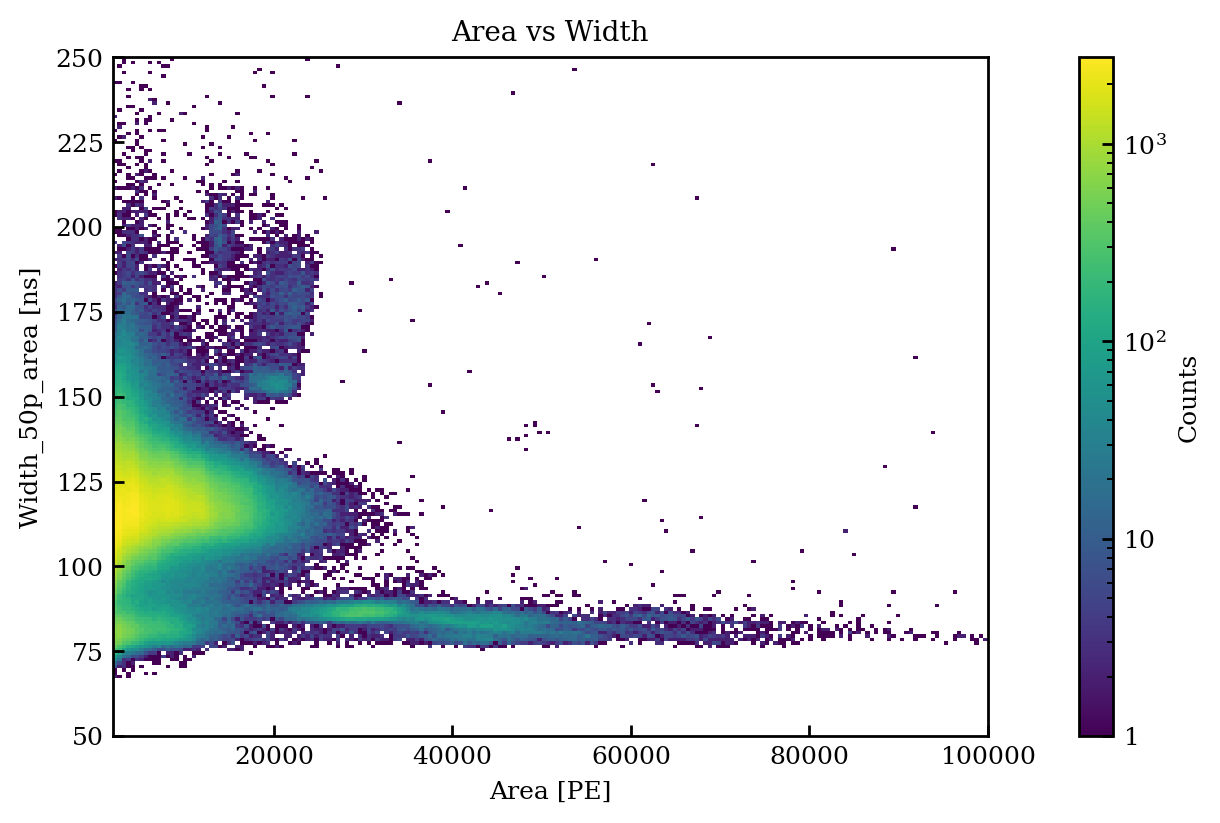

In [39]:
fig, ax = plt.subplots(figsize=(6,4))
h = ax.hist2d(
    df['area'], 
    df['range_50p_area'],
    bins=[200, 200],
    range=[[2e3, 100e3], [50, 250]],
    cmin=1,
    norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('Area [PE]')
ax.set_ylabel('Width_50p_area [ns]')
ax.set_title('Area vs Width')
plt.show()

# FV + Z Combined Correction

The goal is to **narrow the alpha bands** in the Area-vs-AFT plot by correcting for position-dependent light collection efficiency:

1. **FV (radial) correction**: Light collection drops near the TPC walls. We fit the radial dependence in r² and divide it out.
2. **Z (AFT) correction**: Light collection varies with depth (AFT proxy). We fit the band centerline vs AFT and divide it out.

**Correction order matters**: FV first (on raw area in a narrow AFT slice), then Z on top of the FV-corrected area.

All functions are defined inline in the cell below — no external files needed.

In [ ]:
# ═══════════════════════════════════════════════════════════════
# Correction functions (embedded inline — no local .py files needed)
# ═══════════════════════════════════════════════════════════════
from scipy.optimize import curve_fit

def linear_func(x, a, b):
    """Linear function: a*x + b.  x = r² in cm²."""
    return a * x + b

def exp_bump_model(x, a, b, c, d, e):
    """Florian's empirical model for the alpha band: area vs AFT."""
    return a * np.exp((x + b) / c) * (1 - np.exp((x + b) / d)) + e

def plot_r2_dependence(df, r2_col='r2', aft_range=(0.12, 0.55)):
    """Diagnostic: Area vs r² before correction."""
    mask = ((df['area_fraction_top'] >= aft_range[0]) &
            (df['area_fraction_top'] <= aft_range[1]) &
            (df[r2_col] > 0) & (df[r2_col] < 6e3))
    d = df.loc[mask]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ax = axes[0]
    h = ax.hist2d(d[r2_col], d['area'], bins=100,
                  range=[[0, 6e3], [20e3, 100e3]], cmin=1,
                  norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
    ax.set_xlabel('r² [cm²]'); ax.set_ylabel('Area [PE]')
    ax.set_title('Area vs r² (before FV correction)')
    ax = axes[1]
    r2_edges = np.linspace(0, 6e3, 31)
    d = d.copy(); d['r2_bin'] = pd.cut(d[r2_col], bins=r2_edges)
    med = d.groupby('r2_bin', observed=True)['area'].median()
    cents = med.index.map(lambda iv: iv.mid).astype(float).values
    ax.plot(cents, med.values, 'o-', color='red', lw=2)
    ax.set_xlabel('r² [cm²]'); ax.set_ylabel('Median Area [PE]')
    ax.set_title('Median area vs r² (AFT slice)'); ax.grid(True, alpha=0.3)
    plt.tight_layout(); return fig

def apply_fv_correction(df, r2_col='r2', aft_range=(0.12, 0.55),
                        r2_range=(0, 5e3), n_r2_bins=30, plot_fit=True):
    """Fit area vs r² in narrow AFT slice, divide out radial dependence."""
    df = df.copy()
    mask = ((df['area_fraction_top'] >= aft_range[0]) &
            (df['area_fraction_top'] <= aft_range[1]) &
            (df[r2_col] >= r2_range[0]) & (df[r2_col] <= r2_range[1]))
    df_slice = df.loc[mask].copy()
    r2_edges = np.linspace(r2_range[0], r2_range[1], n_r2_bins + 1)
    df_slice['r2_bin'] = pd.cut(df_slice[r2_col], bins=r2_edges)
    medians = df_slice.groupby('r2_bin', observed=True)['area'].median()
    counts = df_slice.groupby('r2_bin', observed=True)['area'].count()
    r2_c = medians.index.map(lambda iv: iv.mid).astype(float).values
    m_areas = medians.values
    good = counts.values >= 10
    r2_c, m_areas = r2_c[good], m_areas[good]
    if len(r2_c) < 5:
        print("FV correction: too few bins, skipping")
        df['area_fv_corrected'] = df['area']; return df, (0, np.median(df['area']))
    try:
        popt, pcov = curve_fit(linear_func, r2_c, m_areas, p0=[0.005, np.median(m_areas)], maxfev=10000)
        perr = np.sqrt(np.diag(pcov))
        print(f"FV fit: slope={popt[0]:.6f}±{perr[0]:.6f} PE/cm², intercept={popt[1]:.0f}±{perr[1]:.0f} PE")
    except Exception as e:
        print(f"FV fit failed: {e}"); popt = [0, np.median(m_areas)]; perr = [0, 0]
    area_ref_fv = linear_func(0, *popt)
    cf = np.clip(area_ref_fv / linear_func(df[r2_col].values, *popt), 0.3, 3.0)
    df['area_fv_corrected'] = df['area'] * cf
    df['fv_correction_factor'] = cf
    print(f"Ref area (r²=0) = {area_ref_fv:.0f} PE, correction range: [{cf.min():.3f}, {cf.max():.3f}]")
    if plot_fit:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.errorbar(r2_c, m_areas, yerr=np.sqrt(m_areas)/np.sqrt(counts[good].values), fmt='o', capsize=3)
        r2_fine = np.linspace(0, r2_range[1], 200)
        ax.plot(r2_fine, linear_func(r2_fine, *popt), 'r-', lw=2)
        ax.axhline(area_ref_fv, color='gray', ls='--', label=f'Ref={area_ref_fv:.0f} PE')
        ax.set_xlabel('r² [cm²]'); ax.set_ylabel('Area [PE]')
        ax.set_title('FV correction fit'); ax.legend(); ax.grid(True, alpha=0.3)
        plt.tight_layout(); plt.show()
    return df, popt

def apply_aft_correction(df, area_col='area_fv_corrected',
                         aft_range=(0.12, 0.55), aft_ref=0.30, n_aft_bins=50,
                         band_upper_pars=None, band_lower_pars=None, plot_fit=True):
    """Fit alpha band centerline vs AFT, divide out depth dependence."""
    df = df.copy()
    mask_fv = ((df['area_fraction_top'] >= aft_range[0]) &
               (df['area_fraction_top'] <= aft_range[1]))
    dfsub = df.loc[mask_fv].copy()
    if band_upper_pars is not None and band_lower_pars is not None:
        dfsub['in_rn_band'] = ((dfsub[area_col] < exp_bump_model(dfsub['area_fraction_top'], *band_upper_pars)) &
                               (dfsub[area_col] > exp_bump_model(dfsub['area_fraction_top'], *band_lower_pars)))
    else:
        dfsub['in_rn_band'] = ((dfsub[area_col] > 30e3) & (dfsub[area_col] < 55e3))
    print(f"Events in Rn band: {dfsub['in_rn_band'].sum()}")
    aft_edges = np.linspace(aft_range[0], aft_range[1], n_aft_bins + 1)
    dfsub['aft_bin'] = pd.cut(dfsub['area_fraction_top'], bins=aft_edges)
    medians_rn = dfsub[dfsub['in_rn_band']].groupby('aft_bin', observed=True)[area_col].median()
    aft_c = medians_rn.index.map(lambda iv: iv.mid).astype(float).values
    m_vals = medians_rn.values
    good = ~np.isnan(m_vals); aft_c, m_vals = aft_c[good], m_vals[good]
    print(f"Fitting AFT with {len(aft_c)} bins")
    p0 = [4.5e4, -0.05, -0.1, -0.05, 35e3]
    popt, pcov = curve_fit(exp_bump_model, aft_c, m_vals, p0=p0,
                           bounds=([0,-np.inf,-np.inf,-np.inf,0], [np.inf,0,0,0,np.inf]), maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    for n, v, e in zip(['a','b','c','d','e'], popt, perr):
        print(f"  {n} = {v:.6e} ± {e:.6e}")
    area_ref_aft = exp_bump_model(aft_ref, *popt)
    print(f"Ref area (AFT={aft_ref}) = {area_ref_aft:.0f} PE")
    af = np.clip(area_ref_aft / exp_bump_model(df['area_fraction_top'].values, *popt), 0.3, 3.0)
    df['area_z_corrected'] = df[area_col] * af
    df['aft_correction_factor'] = af
    print(f"AFT correction range: [{af.min():.3f}, {af.max():.3f}]")
    if plot_fit:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(m_vals, aft_c, 'o', color='lime', markersize=5)
        aft_fine = np.linspace(aft_range[0], aft_range[1], 200)
        ax.plot(exp_bump_model(aft_fine, *popt), aft_fine, 'r-', lw=2)
        ax.axvline(area_ref_aft, color='gray', ls='--', label=f'Ref={area_ref_aft:.0f} PE')
        ax.set_xlabel('Area [PE]'); ax.set_ylabel('Area Fraction Top')
        ax.set_title('AFT correction fit'); ax.legend(); ax.grid(True, alpha=0.3)
        plt.tight_layout(); plt.show()
    return df, popt

def plot_correction_comparison(df, area_cols=None):
    """Side-by-side Area vs AFT at each correction stage."""
    if area_cols is None:
        area_cols = {}
        for label, col in [('Raw','area'),('FV-corrected','area_fv_corrected'),('FV+Z-corrected','area_z_corrected')]:
            if col in df.columns: area_cols[label] = col
    n = len(area_cols)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 5.5), squeeze=False)
    for ax, (label, col) in zip(axes[0], area_cols.items()):
        h = ax.hist2d(df[col], df['area_fraction_top'], bins=[200,200],
                      range=[[20e3,100e3],[0.1,0.65]], cmin=1, norm=matplotlib.colors.LogNorm())
        plt.colorbar(h[3], ax=ax, label='Counts')
        ax.set_xlabel('Area [PE]'); ax.set_ylabel('Area Fraction Top')
        ax.set_title(label); ax.grid(True, alpha=0.2)
    fig.suptitle('Area vs AFT — correction stages', fontsize=14, y=1.02)
    plt.tight_layout(); return fig

def quantify_band_width(df, area_cols=None, aft_range=(0.15, 0.46), area_range=(35e3, 50e3)):
    """Compute band width metrics at each stage. Narrower = better."""
    if area_cols is None:
        area_cols = {'Raw':'area','FV-corrected':'area_fv_corrected','FV+Z-corrected':'area_z_corrected'}
    mask = ((df['area_fraction_top'] >= aft_range[0]) & (df['area_fraction_top'] <= aft_range[1]))
    print(f"{'Stage':20s}  {'μ':>8s}  {'σ':>8s}  {'IQR':>8s}  {'FWHM_est':>10s}  {'n':>8s}")
    print("-"*70)
    results = {}
    for label, col in area_cols.items():
        if col not in df.columns: continue
        data = df.loc[mask, col].dropna()
        data = data[(data >= area_range[0]) & (data <= area_range[1])]
        r = {'mean':data.mean(),'std':data.std(),'median':data.median(),
             'iqr':data.quantile(0.75)-data.quantile(0.25),'fwhm_est':2.355*data.std(),'n':len(data)}
        results[label] = r
        print(f"{label:20s}  {r['mean']:8.0f}  {r['std']:8.0f}  {r['iqr']:8.0f}  {r['fwhm_est']:10.0f}  {r['n']:8d}")
    return results

In [ ]:
# ============================================================
# STEP 2: Apply FV correction (radial, via r²)
# ============================================================
# Fits area vs r² in a narrow AFT slice to isolate radial dependence,
# then divides out the radial variation.
#
# This adds columns: area_fv_corrected, fv_correction_factor
#
# Uses the S1-only df (already filtered to type==1 + area/width ROI).

df_fv, fv_popt = apply_fv_correction(
    df,
    r2_col='r2',
    aft_range=(0.12, 0.55),
    r2_range=(0, 5e3),
    plot_fit=True
)
plt.show()

In [ ]:
# ============================================================
# STEP 3: Apply Z/AFT correction on top of FV-corrected area
# ============================================================
# Fits exp_bump_model to the band centerline in area_fv_corrected vs AFT,
# then divides out the AFT dependence.
#
# This adds columns: area_z_corrected, aft_correction_factor
#
# The Rn band boundaries (band_upper_pars, band_lower_pars) can be tuned
# if the fit picks up the wrong band. Set to None for automatic range.

df_fv, aft_popt = apply_aft_correction(
    df_fv,
    area_col='area_fv_corrected',
    aft_range=(0.12, 0.55),
    aft_ref=0.30,
    band_upper_pars=None,   # use auto range [30k, 55k] PE
    band_lower_pars=None,
    plot_fit=True
)
plt.show()

In [ ]:
# ============================================================
# STEP 4: Before/After comparison
# ============================================================
# Side-by-side Area vs AFT at each correction stage.
# If the corrections work, the bands should become more vertical
# (less AFT dependence) and narrower.

fig_comp = plot_correction_comparison(df_fv)
plt.show()

In [ ]:
# ============================================================
# STEP 5: Quantitative comparison — band width metrics
# ============================================================
# Lower σ, IQR, and FWHM after correction = narrower band = better.
# The improvement is most visible after Z+FV correction.

results = quantify_band_width(
    df_fv,
    aft_range=(0.15, 0.46),
    area_range=(35e3, 50e3)
)

print("\nDone! If σ decreased from Raw → FV+Z-corrected, the correction is working.")
print("You can tune the FV fit range and AFT band boundaries for better results.")